# Qiskit Fall Fest: Quantum Wasserstein GAN (W-QGAN)
## Learning a Critical Many-Body Ground State — plus Thermal States, Dynamics & Real Hardware
> Cells containing `TODO` have empty functions: only their signature (with the types of inputs and outputs) and a short hint are given. Writing the experiments is up to you. A few checks (`assert`) catch common mistakes; passing them does not mean an implementation is 100% correct.

In this challenge you will build a quantum generative adversarial network that learns to prepare the ground state of the critical 1D transverse-field Ising model, and then extend it in one direction of your choice.

### Roadmap
* **Section 0 — Introduction to QGANs:** a one-qubit warm-up.
* **Section 1 — The target state:** the critical Ising chain and its exact ground state.
* **Section 2 — The generator:** a parameterized circuit that respects the symmetry of the model.
* **Section 3 — The critic and the training loop.**
* **Section 4 — Experiments:** training, entanglement and barren plateaus.
* **Extension tracks (choose at least one):**
  * **Track A — Thermal states:** prepare finite-temperature Gibbs states with a thermofield-double circuit.
  * **Track B — Real hardware:** run your trained circuit once on an IBM Quantum processor.
  * **Track C — Speed:** vectorize the simulation with JAX.
  * **Track D — Dynamics:** learn the time-evolution operator $U(t) = e^{-iHt}$.
  * **Track E — Open problem:** If you arrive until here, choose your own expansion that will distingish your group from the rest and implement it!

You do **not** need to do everything: Sections 1–4 plus one extension track would be great already. But the more Tracks you can present the better!

In [ ]:
# Run this cell once: it installs the exact package versions this notebook was tested with (Python 3.11 - 3.14).
# If it upgrades packages that were already imported, restart the kernel before running the next cells.
# Windows on ARM (e.g. Snapdragon laptops): install the x64 build of Python; Qiskit has no native ARM64 Windows wheels.
%pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" "numpy==2.4.4" "scipy==1.17.1" "matplotlib==3.10.9"
# Track C only. JAX publishes no wheels for Intel Macs, so the marker skips it there automatically.
%pip install -q "jax==0.10.2; platform_system != 'Darwin' or platform_machine == 'arm64'" "jaxlib==0.10.2; platform_system != 'Darwin' or platform_machine == 'arm64'"

In [1]:
# Environment Configuration and Imports
import sys
import numpy as np
import scipy.linalg as la
from scipy.sparse.linalg import eigsh
import matplotlib.pyplot as plt
from typing import List, Optional, Tuple

import qiskit
from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector, DensityMatrix, partial_trace, state_fidelity, Operator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

print(f"Python version: {sys.version.split()[0]}")
print(f"Qiskit version: {qiskit.__version__}")
print(f"NumPy version: {np.__version__}")

Python version: 3.11.11
Qiskit version: 2.5.0
NumPy version: 2.2.4


---
## Section 0: Introduction to QGANs

### Generative adversarial networks in one paragraph
A GAN is a game between two players. The **generator** tries to produce samples that look like the training data; the **discriminator** (here called the **critic**) tries to tell generated samples from real ones. Training alternates between improving the critic and improving the generator, until the critic can no longer tell them apart.

### The quantum version
In a quantum GAN (QGAN), the generator is a **parameterized quantum circuit** that prepares a state $\rho_{\boldsymbol{\theta}}$, and the "data" is a target quantum state $\rho_{\text{real}}$. Our critic looks at both states through a few **measurements**: it measures observables $\mathcal{O}_k$ and combines the results with weights $\phi_k$,
$$\mathcal{L}(\boldsymbol{\theta}, \boldsymbol{\phi}) = \sum_k \phi_k \left( \langle \mathcal{O}_k \rangle_{\text{real}} - \langle \mathcal{O}_k \rangle_{\boldsymbol{\theta}} \right).$$
* The critic **maximizes** $\mathcal{L}$, with bounded weights $\sum_k |\phi_k| \le 1/2$: it puts its weight on the observables where the two states differ most.
* The generator **minimizes** $\mathcal{L}$: it changes $\boldsymbol{\theta}$ until the measured expectation values match the target.

> *Why a bound?* Without it, the critic could make $\mathcal{L}$ arbitrarily large just by scaling $\boldsymbol{\phi}$ up, and the game would never settle. The specific choice, an $\ell_1$ bound of radius $1/2$, makes the critic's best value a lower bound on a true distance between quantum states. Section 3 explains where it comes from.

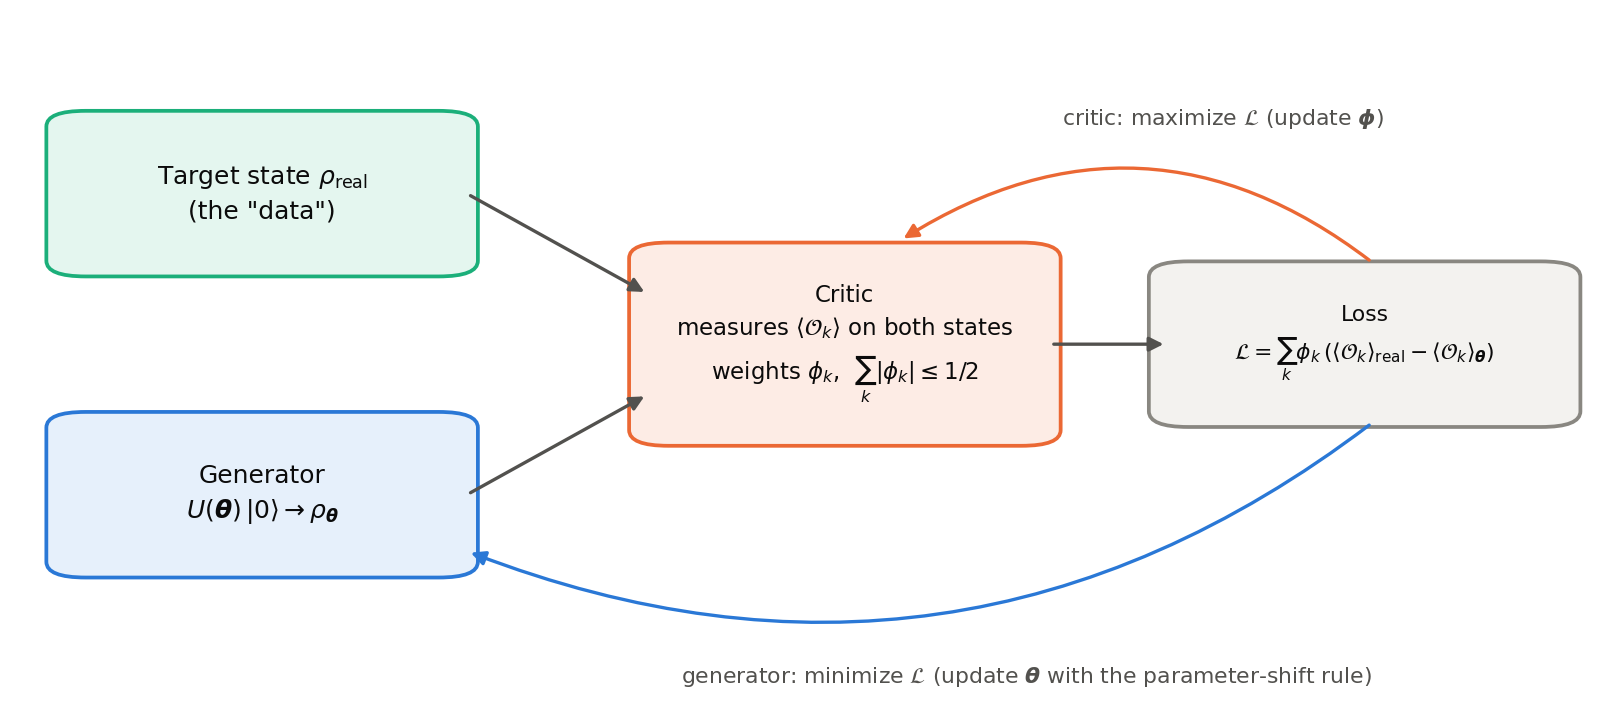

This kind of critic is a simplified *Wasserstein* distance; we come back to it in Section 3.

In [2]:
# The condition on the critic weights is given, you just need to know when to apply it.

RADIUS = 0.5  # bound on the critic weights: sum_k |phi_k| <= RADIUS


def project_to_l1_ball(v: np.ndarray, radius: float = 1.0) -> np.ndarray:
    """Exact Euclidean projection onto the L1-ball: min ||w - v||_2 subject to ||w||_1 <= radius (Duchi et al., 2008)."""
    if np.sum(np.abs(v)) <= radius:
        return v
    u = np.sort(np.abs(v))[::-1]
    sv = np.cumsum(u)
    rho = np.where(u > (sv - radius) / (np.arange(len(u)) + 1))[0][-1]
    theta = (sv[rho] - radius) / (rho + 1)
    return np.sign(v) * np.maximum(np.abs(v) - theta, 0)


### Warm-up: a one-qubit QGAN
Complete the next cell: train the generator $R_Z(\theta_2) R_Y(\theta_1)|0\rangle$ to reproduce a one-qubit target state, with a critic that measures $X$, $Y$ and $Z$.
The generator gradient uses the **parameter-shift rule**, exact for gates $e^{-i\theta P/2}$ with $P$ a Pauli operator:
$$\frac{\partial \langle \mathcal{O} \rangle}{\partial \theta_j} = \frac{\langle \mathcal{O} \rangle_{\boldsymbol{\theta} + \frac{\pi}{2}\mathbf{e}_j} - \langle \mathcal{O} \rangle_{\boldsymbol{\theta} - \frac{\pi}{2}\mathbf{e}_j}}{2}$$
Sections 3 and 4 use exactly the same algorithm for a 6-qubit many-body state.

*Try it:* set different `POOL = ...`. Why does the fidelity reach 1 for some cases but no others?

*Try it*, keep the generator state fixed and run only the critic's projected gradient ascent. Then replace `project_to_l1_ball` with a projection onto the Euclidean ball $\|\boldsymbol{\phi}\|_2 \le 1/2$ (just rescale: `v * min(1, RADIUS / np.linalg.norm(v))`). Show that the critic then converges to $\frac{1}{2}\|\mathbf{v}_{\text{real}} - \mathbf{v}_{\boldsymbol{\theta}}\|_2$, which equals the trace distance between the two states (the exact Wasserstein-1 distance for one qubit), while the $\ell_1$ critic only reaches $\frac{1}{2}\max_k |\Delta_k|$. Section 3 explains what this simplification costs for many qubits.

*References:* Goodfellow et al. (2014), *Generative adversarial nets*, NeurIPS 27. · Lloyd & Weedbrook (2018), *Quantum generative adversarial learning*, Phys. Rev. Lett. 121, 040502.

In [3]:
# Section 0: One-qubit warm-up QGAN

POOL = ["Z"]  # observables measured by the critic (try different POOLs = ['Z'], ['X', 'Y'], ...)


# The "data": a fixed one-qubit target state, R_Z(0.7) R_Y(1.2)|0> up to a global phase
toy_target = Statevector([np.cos(0.6), np.exp(0.7j) * np.sin(0.6)])


def toy_state(x: np.ndarray) -> Statevector:

    """TODO: return the generator output R_Z(x[1]) R_Y(x[0]) |0>."""
    qc=QuantumCircuit(1)
    # Primer fem el segon, després el primer
    qc.ry(x[0],0)
    qc.rz(x[1],0)

    return Statevector(qc)


def toy_expectations(x: np.ndarray) -> np.ndarray:
    """TODO: return the array of <P> for every Pauli label P in POOL (hint: SparsePauliOp('X'))."""
    # La llista de resultats sobre la que guardar cada iteració
    llista_resultats=[]
    # Cridar a la funció anterior
    estat = toy_state(x)
    for operador in POOL:
        pauli_op=SparsePauliOp(operador)
        exp_value=np.real(estat.expectation_value(pauli_op))
        llista_resultats.append(exp_value)

    return np.array(llista_resultats)


def train_toy_qgan(
    x0: np.ndarray, steps: int = 60, lr_g: float = 2.0, lr_d: float = 0.5
) -> Tuple[np.ndarray, List[float]]:
    """TODO: adversarial training; return (final parameters, fidelity with toy_target after every step).
    Each step: gradient ascent of the critic weights followed by project_to_l1_ball(..., RADIUS), then gradient
    descent of the generator parameters with the parameter-shift rule."""
    # Generar les còpies base per a a fidelitats i pesos 
    x=x0.copy()
    historial_fidelitats=[]
    pesos_critic = np.zeros(len(POOL))
    # Calcular les esperances reals:
    valors_reals = np.array([np.real(toy_target.expectation_value(SparsePauliOp(p))) for p in POOL])        
    gradient_g = np.zeros_like(x)

    for valor in range(steps):
        valors_theta=toy_expectations(x)
        # Calcula el gradient com la projecció de la dif de l'esperada i real multiplicada per paràmetre d'aprenentatge lr_d
        pesos_critic=project_to_l1_ball(pesos_critic+lr_d * (valors_reals-valors_theta), RADIUS)
        # Generador 
        for i in range(len(x)):       
            x_plus = x.copy()
            x_minus = x.copy()
            x_plus[i] += np.pi/2
            x_minus[i] -= np.pi/2

            # Calculem el gradient dels valors esperats
            gradient_valors_esperats=(toy_expectations(x_plus)-toy_expectations(x_minus))/2

            # Gradient de L a partir del gradi
            gradient_g[i] = -np.dot(pesos_critic, gradient_valors_esperats)

        # Fer la x anterior - el gradient*pas de gradient    
        x-=lr_g*gradient_g
        historial_fidelitats.append(state_fidelity(toy_state(x), toy_target))

    return (x, historial_fidelitats)



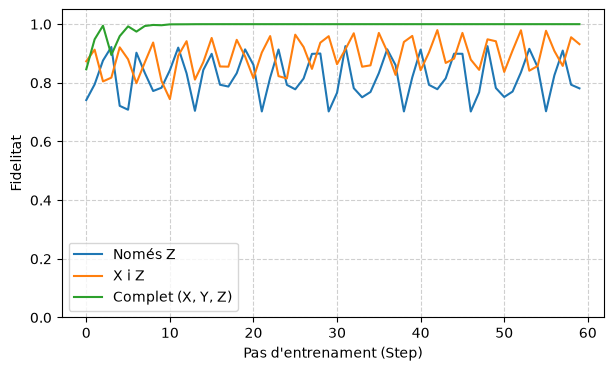

"El resultat s'expliquen per la no commutativitat\nCom que els operadors de Pauli no commuten entre si (\\([X, Z] \neq 0\\), etc.), és impossible canviar \nla projecció d'un eix sense alterar simultàniament la dels altres. Quan el generador fa un pas per apropar \n\\(\\langle X \rangle\\) al valor real, la curvatura de l'esfera de Bloch l'obliga a modificar \\(\\langle Z \rangle\\) \no \\(\\langle Y \rangle\\).\nSuma de valors esperats dels tres eixos al quadrat =1"

In [4]:
# TODO: train from x0 = [0.1, 0.1] with different pools, and plot the different fidelities curves against the step.
# Can you explain the differences you observe?


"""REPRENTACIÓ GRÀFICA DE LES FUNCIONS DE LA SECCIÓ 0"""
pools_a_provar = {
    "Només Z": ["Z"],
    "X i Z": ["X", "Z"],
    "Complet (X, Y, Z)": ["X", "Y", "Z"],
}

x0 = np.array([0.1, 0.1])
resultats_fidelitat = {}

global POOL
for nom, pool in pools_a_provar.items():
    POOL = pool
    _, fidelitats = train_toy_qgan(x0, steps=60, lr_g=2.0, lr_d=0.5)
    resultats_fidelitat[nom] = fidelitats

# Gràfica comparativa
plt.figure(figsize=(7, 4))
for nom, fidelitats in resultats_fidelitat.items():
    plt.plot(fidelitats, label=nom)

plt.xlabel("Pas d'entrenament (Step)")
plt.ylabel("Fidelitat")
plt.ylim(0, 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

"""El resultat s'expliquen per la no commutativitat
Com que els operadors de Pauli no commuten entre si (\([X, Z] \neq 0\), etc.), és impossible canviar 
la projecció d'un eix sense alterar simultàniament la dels altres. Quan el generador fa un pas per apropar 
\(\langle X \rangle\) al valor real, la curvatura de l'esfera de Bloch l'obliga a modificar \(\langle Z \rangle\) 
o \(\langle Y \rangle\).
Suma de valors esperats dels tres eixos al quadrat =1"""

In [5]:
"""Try it, keep the generator state fixed and run only the critic's projected gradient ascent. Then replace project_to_l1_ball 
with a projection onto the Euclidean ball 
 (just rescale: v * min(1, RADIUS / np.linalg.norm(v))). Show that the critic then converges to ...
, which equals the trace distance between the two states (the exact Wasserstein-1 distance for one qubit), while the 
 critic only reaches ... . Section 3 explains what this simplification costs for many qubits."""

# 1. Configuració inicial amb estat fix i base tomogràfica completa
POOL = ["X", "Y", "Z"]
RADIUS = 0.5
x_fix = np.array([0.1, 0.1])

# Esperances fixes del generador i de l'objectiu
v_real = np.array([np.real(toy_target.expectation_value(SparsePauliOp(p))) for p in POOL])
v_theta = toy_expectations(x_fix)
delta = v_real - v_theta  # Vector de diferències a l'esfera de Bloch

# Valors teòrics de convergència
distancia_traca_teorica = 0.5 * np.linalg.norm(delta)  # Equival a 0.5 * ||v_real - v_theta||_2
limit_l1_teoric = 0.5 * np.max(np.abs(delta))         # Equival a 0.5 * max_k |Delta_k|

# 2. Definició de la projecció a la bola euclidiana L2
def project_to_l2_ball(v: np.ndarray, radius: float = 0.5) -> np.ndarray:
    norm = np.linalg.norm(v)
    if norm <= radius or norm == 0:
        return v
    return v * (radius / norm)

# 3. Ascens de gradient projectat per a ambdós crítics (generador fix)
def entrenar_critic_fix(projeccio_func, steps: int = 100, lr_d: float = 0.1) -> List[float]:
    phi = np.zeros(len(POOL))
    historial_valor_critic = []
    for _ in range(steps):
        # Ascens de gradient: pas cap a delta
        phi = projeccio_func(phi + lr_d * delta, radius=RADIUS)
        # Valor de la funció objectiu L(phi) = phi^T (v_real - v_theta)
        historial_valor_critic.append(float(np.dot(phi, delta)))
    return historial_valor_critic

valors_l1 = entrenar_critic_fix(project_to_l1_ball)
valors_l2 = entrenar_critic_fix(project_to_l2_ball)

# 4. Comprovació dels resultats numèrics
print(f"--- Crític L2 (Euclidià) ---")
print(f"Convergència numèrica: {valors_l2[-1]:.8f}")
print(f"Teòric (Distància de traça): {distancia_traca_teorica:.8f}")

print(f"\n--- Crític L1 ---")
print(f"Convergència numèrica: {valors_l1[-1]:.6f}")
print(f"Teòric (0.5 * max|Delta|):   {limit_l1_teoric:.6f}")

--- Crític L2 (Euclidià) ---
Convergència numèrica: 0.53040370
Teòric (Distància de traça): 0.53040370

--- Crític L1 ---
Convergència numèrica: 0.313371
Teòric (0.5 * max|Delta|):   0.316323


---
## Section 1: The Target — Ground State of the Critical Ising Chain

The 1D Transverse Field Ising Model (TFIM) with open boundary conditions across $N$ sites is:
$$H = -J \sum_{i=0}^{N-2} Z_i Z_{i+1} - h \sum_{i=0}^{N-1} X_i$$
At $h/J = 1$ the chain sits at a quantum phase transition (the critical point) between an ordered phase ($h < J$) and a disordered phase ($h > J$). $H$ commutes with the global spin-flip (parity) operator $\Pi = \bigotimes_{i} X_i$, and its ground state has $\Pi = +1$; Section 2 uses this.

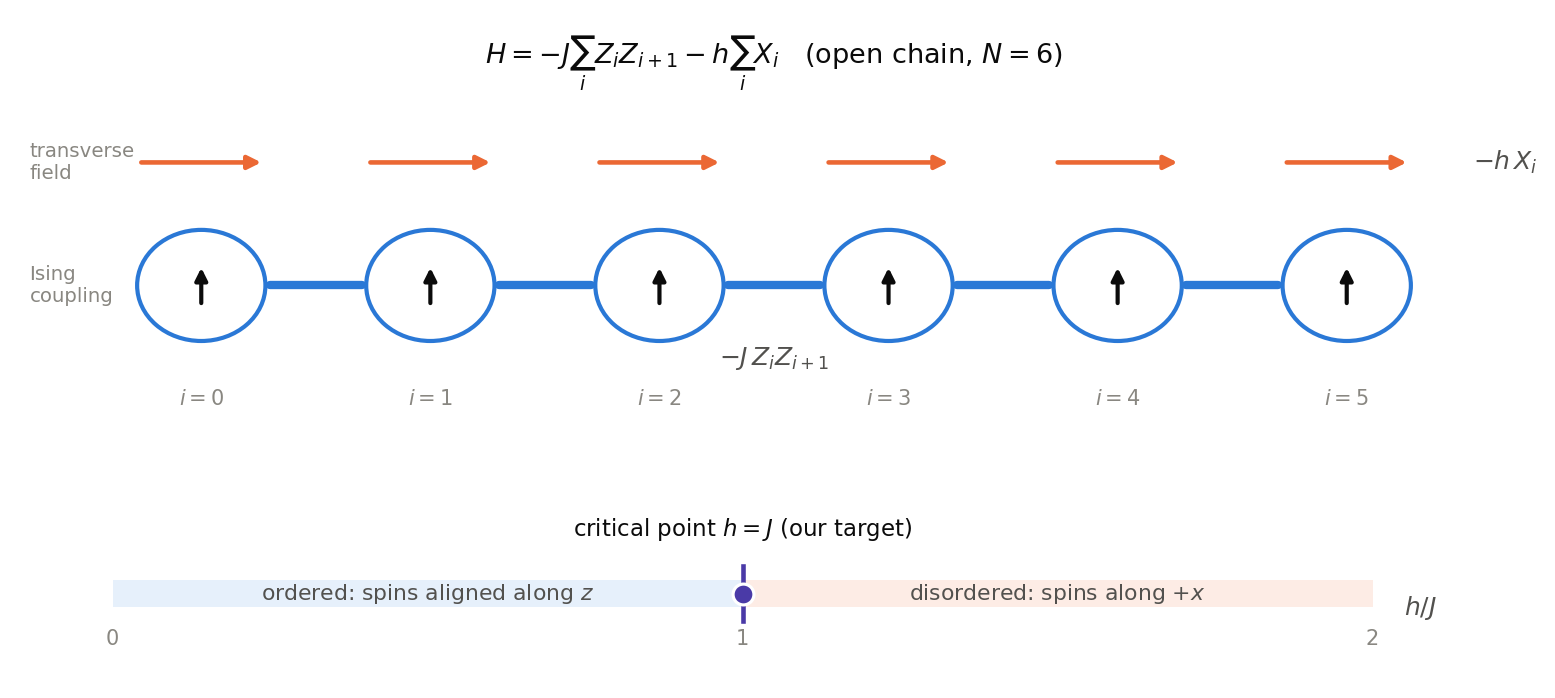

### Objectives
1. Construct the critical TFIM Hamiltonian ($J=1.0, h=1.0$) with open boundaries.
2. Calculate the exact ground state $|\psi_0\rangle$ and ground energy $E_0$ via exact diagonalization.
3. Construct the local observable pool $\mathcal{S} = \{ X_i \}_{i=0}^{N-1} \cup \{ Z_i Z_{i+1} \}_{i=0}^{N-2}$ of size $M = 2N - 1$.
4. Calculate the exact target expectation values $\mathbf{v}_{\text{real}}$ and the half-chain von Neumann entanglement entropy $S(\rho_A) = -\operatorname{Tr}[\rho_A \log_2 \rho_A]$.

> **Qubit ordering:** Qiskit is little-endian — in a Pauli label the *rightmost* character acts on qubit 0 (`'XIII'` is $X_3$, not $X_0$).

*Reference:* Pfeuty (1970), *The one-dimensional Ising model with a transverse field*, Ann. Phys. 57, 79.

In [6]:
# Section 1: Exact TFIM Ground State Baseline and Local Observable Pool


def build_tfim_hamiltonian(num_qubits: int, J: float = 1.0, h: float = 1.0) -> SparsePauliOp:
    """TODO: return the open-chain H = -J sum_i Z_i Z_{i+1} - h sum_i X_i (hint: SparsePauliOp.from_sparse_list)."""
    llista_hamiltonia=[]
    N=num_qubits
    # Fer els sumatoris per a X i per a ZZ
    for i in range (N):
        llista_hamiltonia.append(["X", [i],-h])

    for i in range (N-1):
        llista_hamiltonia.append(["ZZ", [i,i+1],-J])
    # La funció from_sparse_list compila amb les identitats a afegir entremig
    return SparsePauliOp.from_sparse_list(llista_hamiltonia, num_qubits)

def compute_exact_ground_state(hamiltonian: SparsePauliOp) -> Tuple[float, Statevector]:
    """TODO: return (E_0, |psi_0>) by exact diagonalization."""
    # Convertir la llista en una matriu que poder diagonalitzar
    matriu_hamiltonia=hamiltonian.to_matrix()
    # Diagonalització del hamiltonià mitjançant "scipy.linalg" importat com "la"
    autovalors, autovectors=la.eigh(matriu_hamiltonia)
    energia0=autovalors[0]

    # Retornar l'energia fonamental i el seu respectiu autovector (dins la matriu d'autovectors, cada autovector=columna)
    return energia0, Statevector(autovectors[:,0])


def construct_observable_pool(num_qubits: int) -> List[SparsePauliOp]:
    """TODO: return the pool [X_0, ..., X_{N-1}, Z_0 Z_1, ..., Z_{N-2} Z_{N-1}] (in this order)."""
    # Llista on guardarem els operadors.
    observables = []
    # Primer: un operador X per cada qubit.
    for i in range(num_qubits):
        op = SparsePauliOp.from_sparse_list([("X", [i], 1.0)],num_qubits=num_qubits)
        observables.append(op)

    # Després: un operador ZZ per cada parella de veïns.
    for i in range(num_qubits - 1):
        op = SparsePauliOp.from_sparse_list([("ZZ", [i, i + 1], 1.0)],num_qubits=num_qubits)
        observables.append(op)
    return observables

"""Retorna 2N-1 observables ja que per a cada terme del hamiltonià, N termes individual (X)
i N-1 termes d'interaccions de parelles (ZZ): N+N-1=2N-1"""

def compute_von_neumann_entropy(state: Statevector, subsystem_qubits: List[int]) -> float:
    """TODO: return S(rho_A) = -Tr[rho_A log2 rho_A] (bits) for A = subsystem_qubits.
    Hint: partial_trace(state, qargs) traces OUT the qubits listed in qargs."""

    """Calcula l'entropia del subsistema indicat, en bits."""

    # Identifiquem els qubits que NO pertanyen al subsistema.
    qubits_to_trace = [q for q in range(state.num_qubits) if q not in subsystem_qubits]

    # Eliminem aquests qubits i obtenim la matriu de densitat reduïda.
    rho_A = partial_trace(state, qubits_to_trace)

    # Calculem els valors propis de la matriu hermítica rho_A.
    eigenvalues = np.linalg.eigvalsh(rho_A.data)

    # Corregim petits valors negatius causats per errors numèrics.
    eigenvalues = np.clip(eigenvalues, 0.0, 1.0)

    # Excloem els zeros: la seva contribució és 0 log₂(0) = 0.
    eigenvalues = eigenvalues[eigenvalues > 0.0]

    # S(rho_A) = -sum_a lambda_a log₂(lambda_a).
    entropy = -np.sum(eigenvalues * np.log2(eigenvalues))

    return float(entropy)

N_QUBITS = 6
H_tfim = build_tfim_hamiltonian(N_QUBITS, J=1.0, h=1.0)
e_exact, psi_exact = compute_exact_ground_state(H_tfim)
obs_pool = construct_observable_pool(N_QUBITS)
v_real = np.array([float(psi_exact.expectation_value(op).real) for op in obs_pool])
subsystem_A = list(range(N_QUBITS // 2))
entropy_real = compute_von_neumann_entropy(psi_exact, subsystem_A)

# Checks
assert np.isclose(e_exact, -7.29623, atol=1e-5), "E_0 should be -7.29623 for N = 6 and J = h = 1"
assert len(obs_pool) == 2 * N_QUBITS - 1, "The pool should contain 2N - 1 observables"
assert np.isclose(compute_von_neumann_entropy(Statevector([1, 0, 0, 1] / np.sqrt(2)), [0]), 1.0), ("A Bell pair has 1 bit")

---
## Section 2: $\mathbb{Z}_2$ Parity-Preserving Quantum Generator Ansatz

Unconstrained "hardware-efficient" circuits ignore the symmetries of $H$ and explore the whole Hilbert space $(\mathbb{C}^2)^{\otimes N}$. Since $[H, \Pi] = 0$ and the ground state has $\Pi = +1$, we build the generator so that $[U_G(\boldsymbol{\theta}), \Pi] = 0$: the search then stays inside the physical parity sector.

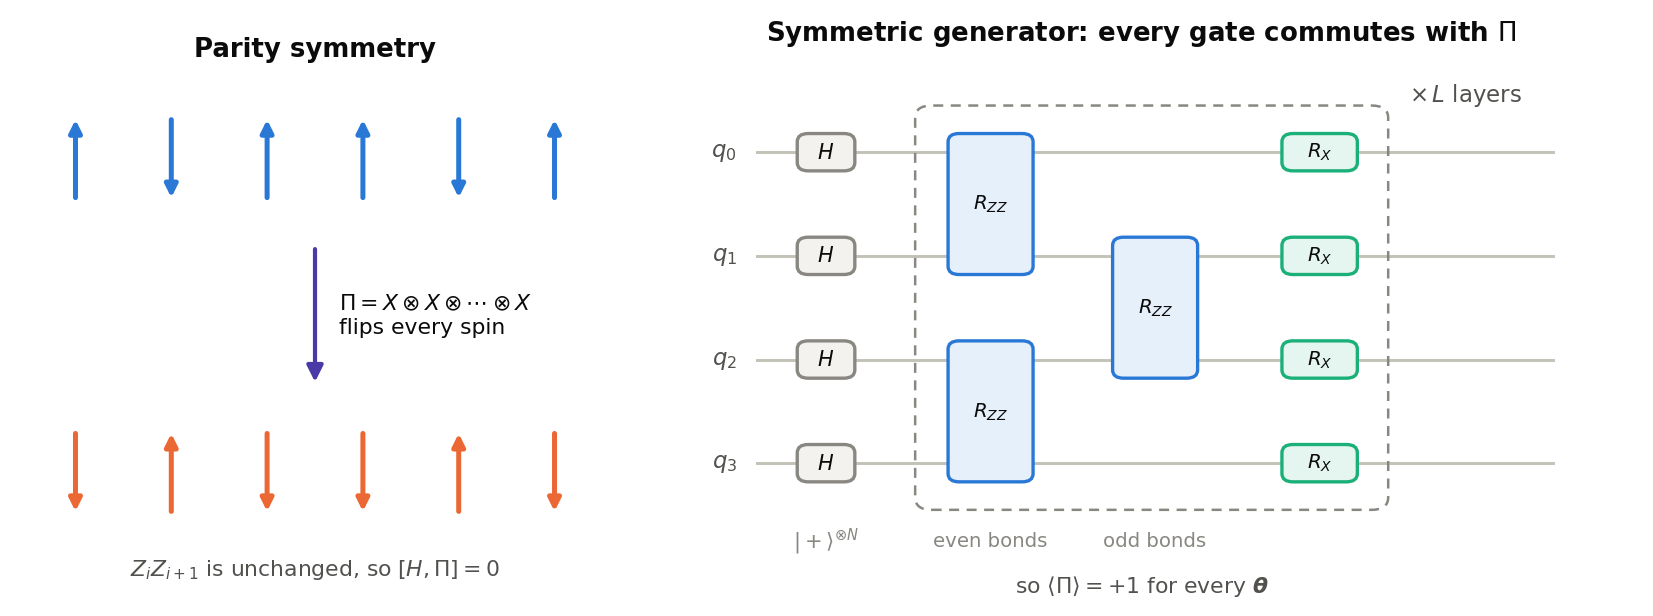

### Mathematical Commutation Proof
The ground state $|\psi_0\rangle$ belongs to the positive parity eigenspace $\Pi |\psi_0\rangle = +|\psi_0\rangle$, where $\Pi = \bigotimes_{i=0}^{N-1} X_i$.
1. **Initial State:** Starting in $|+\rangle^{\otimes N} = H^{\otimes N} |0\rangle^{\otimes N}$ guarantees $\Pi |+\rangle^{\otimes N} = +|+\rangle^{\otimes N}$.
2. **Single-Qubit Rotations:** $R_X(\theta) = \exp(-i \frac{\theta}{2} X)$ commutes with $X$:
   $$[R_X(\theta), X] = 0 \implies \left[\bigotimes_{i} R_X(\theta_i), \Pi\right] = 0$$
3. **Two-Qubit Interactions:** $R_{ZZ}(\theta) = \exp(-i \frac{\theta}{2} Z_i Z_{i+1})$. Under parity conjugation:
   $$\Pi (Z_i Z_{i+1}) \Pi^\dagger = (X_i Z_i X_i) (X_{i+1} Z_{i+1} X_{i+1}) = (-Z_i)(-Z_{i+1}) = Z_i Z_{i+1}$$
   Therefore, $[R_{ZZ}(\theta), \Pi] = 0$.

By induction, any circuit composed of $R_X$ and $R_{ZZ}$ layers acting on $|+\rangle^{\otimes N}$ strictly preserves $\langle \Pi \rangle = +1.0$ for all parameter values $\boldsymbol{\theta}$.

*Implementation note:* the $R_{ZZ}$ gates of one layer commute with each other, so we apply them on the even bonds first and then on the odd bonds — the same unitary with a shallower circuit.

In [7]:
# Section 2: Symmetry-Preserving Ansatz Generator Circuit and Parity Verification

def create_z2_symmetric_generator(num_qubits: int, num_layers: int) -> Tuple[QuantumCircuit, ParameterVector]:
    """TODO: return (circuit, parameters): H on every qubit, then num_layers x [R_ZZ on every bond (i, i+1),
    R_X on every qubit]. One ParameterVector of length (2N - 1) * num_layers; theta[0] must be the first-layer
    R_ZZ angle on bond (0, 1)."""
    qc = QuantumCircuit(num_qubits)

    # 2. Creem els paràmetres. 
    # Per cada capa tenim (num_qubits - 1) portes R_ZZ i num_qubits portes R_X.
    params_per_layer = (2 * num_qubits) - 1 # Te aquest tamany perque les portes Rzz actuen entre veïns i per N qubits tenim N-1 enllaços.
                                            # I despres apliquem les portes Rx als N qubits, per tant, per layer tenim N-1 + N = 2N - 1 parametres,
    theta = ParameterVector('theta', params_per_layer * num_layers)
    
    # 3. Hadamard a cada qubit (fora del bucle de capes)
    for i in range(num_qubits):
        qc.h(i)
        
    # 4. Construïm les capes
    for layer in range(num_layers):
        # Calculem quin és el primer índex de paràmetre d'aquesta capa
        offset = layer * params_per_layer
        
        # Enllaços PARELLS (0-1, 2-3, 4-5...). 
        # range(0, num_qubits - 1, 2) avança de 2 en 2 i evita sortir de rang.
        for i in range(0, num_qubits - 1, 2):
            qc.rzz(theta[offset + i], i, i + 1)
            
        # Enllaços SENARS (1-2, 3-4, 5-6...)
        for i in range(1, num_qubits - 1, 2):
            qc.rzz(theta[offset + i], i, i + 1)
            
        # Portes RX a tots els qubits
        # Els paràmetres RX comencen just després dels paràmetres R_ZZ (que són num_qubits - 1)
        rx_offset = offset + (num_qubits - 1)
        for i in range(num_qubits):
            qc.rx(theta[rx_offset + i], i)
            
    return qc, theta


def test_parity_conservation(qc: QuantumCircuit, theta_params: ParameterVector, samples: int = 5) -> bool:
    """Tests that  == 1.0 for random parameter values."""
    tol = 1e-5
    
    # 1. Construïm l'operador de paritat (una 'X' per cada qubit)
    # Si tenim 6 qubits, això crearà l'string 'XXXXXX'
    num_qubits = qc.num_qubits
    parity_op = SparsePauliOp('X' * num_qubits)
    
    # 2. Fem el test tantes vegades com ens indiqui 'samples'
    for _ in range(samples): #Index mut
        # Generem números aleatoris per a cada paràmetre (entre -pi i pi, per exemple)
        valors_aleatoris = np.random.uniform(-np.pi, np.pi, len(theta_params))
        
        # 'Enxufem' aquests números al circuit. Això ens retorna un circuit amb les thetas com a nombres ja.
        circuit_tancat = qc.assign_parameters(valors_aleatoris)
        
        # Calculem l'estat matemàtic d'aquest circuit específic
        sv = Statevector.from_instruction(circuit_tancat)
        
        # Mesurem el valor esperat de l'operador de paritat i ens quedem amb la part real
        valor_esperat = sv.expectation_value(parity_op).real
        
        # Si la diferència amb 1.0 és més gran que la tolerància, el test falla
        if abs(valor_esperat - 1.0) > tol:
            return False
            
    # Si ha superat totes les voltes del bucle, la paritat es conserva
    return True
# El circuit que hem creat es per aconseguir recrear l'estat fonamental del Model d'Ising. Ara a partir de donar-li molts valors diferents de 
# theta, verifiquem a traves de la paritat que el nostre estat construit mante la propietat de la paritat del d'Ising. Si no ho compleix 
# amb els diferents valors de theta es que ho hem fet malament.

num_layers=5
gen_circuit, theta_params = create_z2_symmetric_generator(N_QUBITS, num_layers)
assert len(theta_params) == (2 * N_QUBITS - 1) * num_layers, "Unexpected number of parameters"
assert test_parity_conservation(gen_circuit, theta_params), "Parity conservation violated!"
print(f"Generator created: {len(theta_params)} parameters, depth {gen_circuit.depth()}")
print("Parity test PASSED: <Pi> = +1 for random parameter values")

Generator created: 55 parameters, depth 16
Parity test PASSED: <Pi> = +1 for random parameter values


---
## Section 3: The Wasserstein Critic & Parameter-Shift Training

### The critic as a restricted Wasserstein distance
The quantum Wasserstein distance of order 1 compares two states through all "smooth" observables. By the quantum Kantorovich–Rubinstein duality:
$$\mathcal{W}_1(\rho_{\text{real}}, \rho_G(\boldsymbol{\theta})) = \max_{\|D\|_{L} \le 1} \operatorname{Tr}\left[ D \left( \rho_{\text{real}} - \rho_G(\boldsymbol{\theta}) \right) \right]$$
where $\|D\|_{L}$ is the quantum Lipschitz constant (how much $\langle D\rangle$ can change when a single qubit is changed). We restrict the critic to our local pool:
$$D_{\boldsymbol{\phi}} = \sum_{k=1}^M \phi_k \mathcal{O}_k, \quad \text{subject to } \|\boldsymbol{\phi}\|_1 = \sum_{k=1}^M |\phi_k| \le \tfrac{1}{2}$$
In this normalization a single Pauli operator has $\|X_i\|_L = \|Z_i Z_{i+1}\|_L = 2$, so by the triangle inequality $\|D_{\boldsymbol{\phi}}\|_L \le 2\|\boldsymbol{\phi}\|_1$ and the bound $1/2$ guarantees $\|D_{\boldsymbol{\phi}}\|_L \le 1$. This is a sufficient condition, not the exact one (see below). The adversarial saddle-point objective becomes:
$$\min_{\boldsymbol{\theta}} \max_{\|\boldsymbol{\phi}\|_1 \le 1/2} \mathcal{L}(\boldsymbol{\theta}, \boldsymbol{\phi}), \qquad \mathcal{L}(\boldsymbol{\theta}, \boldsymbol{\phi}) = \sum_{k=1}^M \phi_k \left( \langle \mathcal{O}_k \rangle_{\text{real}} - \langle \mathcal{O}_k \rangle_{\boldsymbol{\theta}} \right)$$
For a fixed generator, the best critic puts all its weight on the worst-matched observable, so its value is $\tfrac{1}{2}\max_k |\langle \mathcal{O}_k \rangle_{\text{real}} - \langle \mathcal{O}_k \rangle_{\boldsymbol{\theta}}|$, a lower bound on $\mathcal{W}_1$. This is the number we monitor during training. Because the critic weights are bounded, the game cannot diverge, although alternating updates can oscillate.

### What the $\ell_1$ bound costs
The Lipschitz constant only adds up the weights of observables acting on the **same qubit**, $\|D_{\boldsymbol{\phi}}\|_L \le 2 \max_i \sum_{k \ni i} |\phi_k|$. So a valid Wasserstein critic can spend a budget of $1/2$ on *every* qubit, while our $\ell_1$ bound makes all $M$ observables share a *single* budget of $1/2$ (Section 0 showed the one-qubit version of this).
* **Smaller value:** if every qubit has the same error $\delta$ in $\langle X_i\rangle$, the $\ell_1$ critic finds $\tfrac{1}{2}\delta$, but the valid critic $\tfrac{1}{2}\sum_i X_i$ finds $\tfrac{1}{2}N\delta$. Our monitored value measures the *worst local* error, not the total one.
* **Sparser feedback:** the best $\ell_1$ critic puts its weight on one or two observables, so each generator step corrects only those.
* **Same solution:** both critics vanish only when *all* pool expectation values match, so the generator learns the same target. We use $\ell_1$ because its projection and best critic are simple to compute.

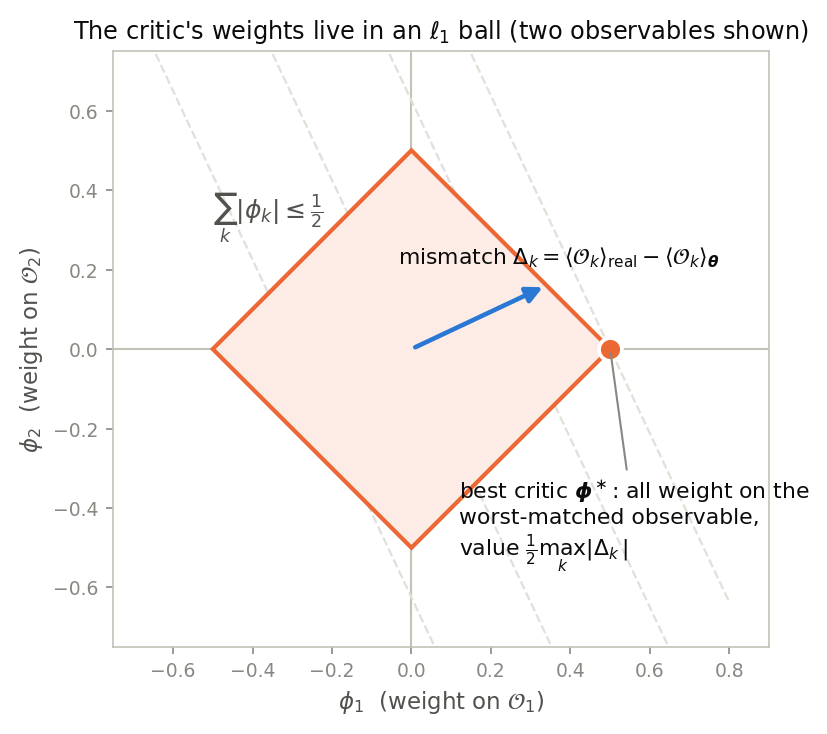

### Optimization Algorithms
1. **Discriminator Projected Gradient Ascent:**
   The discriminator maximizes $\mathcal{L}_D(\boldsymbol{\phi}) = \boldsymbol{\phi}^T (\mathbf{v}_{\text{real}} - \mathbf{v}_{\boldsymbol{\theta}})$ and is kept inside the $\ell_1$-ball of radius $1/2$ by the exact Euclidean projection `project_to_l1_ball` (defined in Section 0):
   $$\boldsymbol{\phi}^{(t+1)} = \mathrm{Proj}_{\|\cdot\|_1 \le 1/2}\left( \boldsymbol{\phi}^{(t)} + \eta_D (\mathbf{v}_{\text{real}} - \mathbf{v}_{\boldsymbol{\theta}}) \right)$$
2. **Generator Analytic Parameter-Shift Descent:**
   Every parameter enters exactly one gate $e^{-i\theta_j P/2}$, so the exact gradient with respect to $\theta_j$ is evaluated without finite differences:
   $$\frac{\partial \langle \mathcal{O}_k \rangle}{\partial \theta_j} = \frac{\langle \mathcal{O}_k \rangle_{\boldsymbol{\theta} + \frac{\pi}{2}\mathbf{e}_j} - \langle \mathcal{O}_k \rangle_{\boldsymbol{\theta} - \frac{\pi}{2}\mathbf{e}_j}}{2}$$
   $$\nabla_{\boldsymbol{\theta}} \mathcal{L}_G = -\sum_{k=1}^M \phi_k \nabla_{\boldsymbol{\theta}} \langle \mathcal{O}_k \rangle_{\boldsymbol{\theta}}, \quad \boldsymbol{\theta}^{(t+1)} = \boldsymbol{\theta}^{(t)} - \eta_G \nabla_{\boldsymbol{\theta}} \mathcal{L}_G$$

*Reference:* De Palma, Marvian, Trevisan & Lloyd (2021), *The quantum Wasserstein distance of order 1*, IEEE Trans. Inf. Theory 67, 6627.

In [8]:
# Section 3: WQGANTrainer Implementation (exact statevector simulation)


class WQGANTrainer:
    """Adversarial W-QGAN optimization engine (exact statevector simulation)."""

    def __init__(
        self,
        circuit: QuantumCircuit,
        parameters: ParameterVector,
        observables: List[SparsePauliOp],
        v_real: np.ndarray,
        target_state: Statevector,
        radius: float = 0.5,
        seed: int = 42,
    ):
        self.circuit = circuit
        self.parameters = parameters
        self.observables = observables
        self.v_real = v_real
        self.target_state = target_state
        self.radius = radius
        self.num_params = len(parameters)
        self.num_obs = len(observables)

        rng = np.random.default_rng(seed)
        self.theta = rng.uniform(-0.1, 0.1, self.num_params)
        self.phi = np.zeros(self.num_obs)

    # Correspondència amb la secció 0: (0-->3)
    # toy_state --> self.circuit 
    # POOL --> self.observables
    # toy_expectations(x)--> evaulate_expectations(theta_vals)
    # Bucle del gradient --> compute_generator_gradient(theta_vals, phi_weights)
    # Cos del bucle, for _ in range(steps) --> train_step(lr_g, lr_d)
    # phi (el pes) i theta estan al self i només s'actualitzen dins del train_step
    
    def evaluate_expectations(self, theta_vals: np.ndarray) -> np.ndarray:
        """TODO: return the array of <O_k> (one per observable) of the generator state for parameters theta_vals."""
        #Asignem els parametres del self al circuit i creem l'statevector del circuit
        psi = Statevector(self.circuit.assign_parameters(theta_vals))
        
        #Retornem els valors esperats pels elements de la llista d'observables (igual que a la secció 0)
        return np.array([psi.expectation_value(op).real for op in self.observables])
        
    def compute_generator_gradient(self, theta_vals: np.ndarray, phi_weights: np.ndarray) -> np.ndarray:
        """TODO: return dL/dtheta (length self.num_params) using the parameter-shift rule."""
        # jac[k, j] = d<O_k>/d theta_j es una matriu
        jac = np.zeros((self.num_obs, self.num_params))      
        for j in range(self.num_params):
            #Podem definir un vector que té pi/2 en la posició j
            e = np.zeros(self.num_params)
            e[j] = np.pi / 2
            #Operem directament en les columnes de jac fent servir la fórmula de la secció 0
            #No cal fer còpies d'aquesta manera
            jac[:, j] = (self.evaluate_expectations(theta_vals + e)
                         - self.evaluate_expectations(theta_vals - e)) / 2
            #Es fa el producte de la fórmula de la secció 0 per tenir el gradient
        return -phi_weights @ jac  
        
    def train_step(self, lr_g: float = 2.0, lr_d: float = 0.5) -> Tuple[float, float, float]:
        """TODO: one adversarial step (critic update, then generator update). Return, at the NEW parameters,
        (best-critic value = W1 lower bound, fidelity with self.target_state, norm of the generator gradient)."""
        #Altre cop,, prácticament igual que a la secció 0. Recordar que phi son els pesos 
        v_theta=self.evaluate_expectations(self.theta)
        self.phi = project_to_l1_ball(self.phi + lr_d * (self.v_real-v_theta), self.radius)

        #Cridem la funció de gradient
        grad = self.compute_generator_gradient(self.theta, self.phi)
        #Mateixa fórmula que a la secció 0
        self.theta-=lr_g*grad

        #Aquesta part a la secció s'ha fet fora de la funció y com a extra conceptual (ho ha fet l'Eric)
        delta_new = self.v_real - self.evaluate_expectations(self.theta)
        w1_lower_bound = self.radius * np.max(np.abs(delta_new))

        #Statevector del circuit amb els parametres reassignats (toy_state(x) a la secció 0)
        psi=Statevector(self.circuit.assign_parameters(self.theta))
        #Igual que a la secció 0 (amb modificacions del self)
        fidelity = state_fidelity(psi, self.target_state)
        return w1_lower_bound, fidelity, np.linalg.norm(grad)


# Check the parameter-shift gradient against a finite difference
check_trainer = WQGANTrainer(gen_circuit, theta_params, obs_pool, v_real, psi_exact, seed=0)
weights = np.random.default_rng(1).normal(size=len(obs_pool))
grad = check_trainer.compute_generator_gradient(check_trainer.theta, weights)
e0, eps = np.eye(len(theta_params))[0], 1e-6
finite_diff = (
    -weights
    @ (
        check_trainer.evaluate_expectations(check_trainer.theta + eps * e0)
        - check_trainer.evaluate_expectations(check_trainer.theta - eps * e0)
    )
    / (2 * eps)
)
assert np.isclose(grad[0], finite_diff, atol=1e-6), "Parameter-shift gradient disagrees with finite differences"
print("WQGANTrainer engine initialized: parameter-shift gradient agrees with finite differences.")

WQGANTrainer engine initialized: parameter-shift gradient agrees with finite differences.


---
## Section 4: Training Execution & Barren Plateau Ablation

### Experiments to Perform
Write the code for these three experiments; the cells below only sketch the functions you need.
1. **Adversarial Training Loop:** Run the minimax optimization and follow the best-critic value ($\mathcal{W}_1$ lower bound) and the state fidelity $\mathcal{F}$.
2. **Entanglement Entropy Recovery:** Compare the half-chain entropy of the trained state with the exact one. At the critical point, conformal field theory predicts that the half-chain entropy of an open chain grows logarithmically with the system size, $S(N/2) \simeq \frac{c}{6}\log_2 N + \text{const}$, with central charge $c = 1/2$. Check this with exact diagonalization for several $N$; small chains show visible finite-size corrections.
3. **Barren Plateau Mitigation:** For random parameters, gradients of *global* costs, such as the fidelity-type projector $\vert{}0^{\otimes N}\rangle\langle 0^{\otimes N}\vert{}$, vanish exponentially with $N$, even for shallow circuits, whereas gradients of *local* observables do not. Quantify the variance of the gradient $\operatorname{Var}_{\boldsymbol{\theta}}[\partial_{\theta_0} \langle O \rangle]$ as a function of qubit count $N \in \{4, 6, 8, 10\}$ comparing:
   * **Local Observable Loss (Wasserstein):** $O_{\text{local}} = X_0$
   * **Global Observable Loss (Fidelity/Projector):** $O_{\text{global}} = \vert{}0^{\otimes N}\rangle\langle 0^{\otimes N}\vert{}$

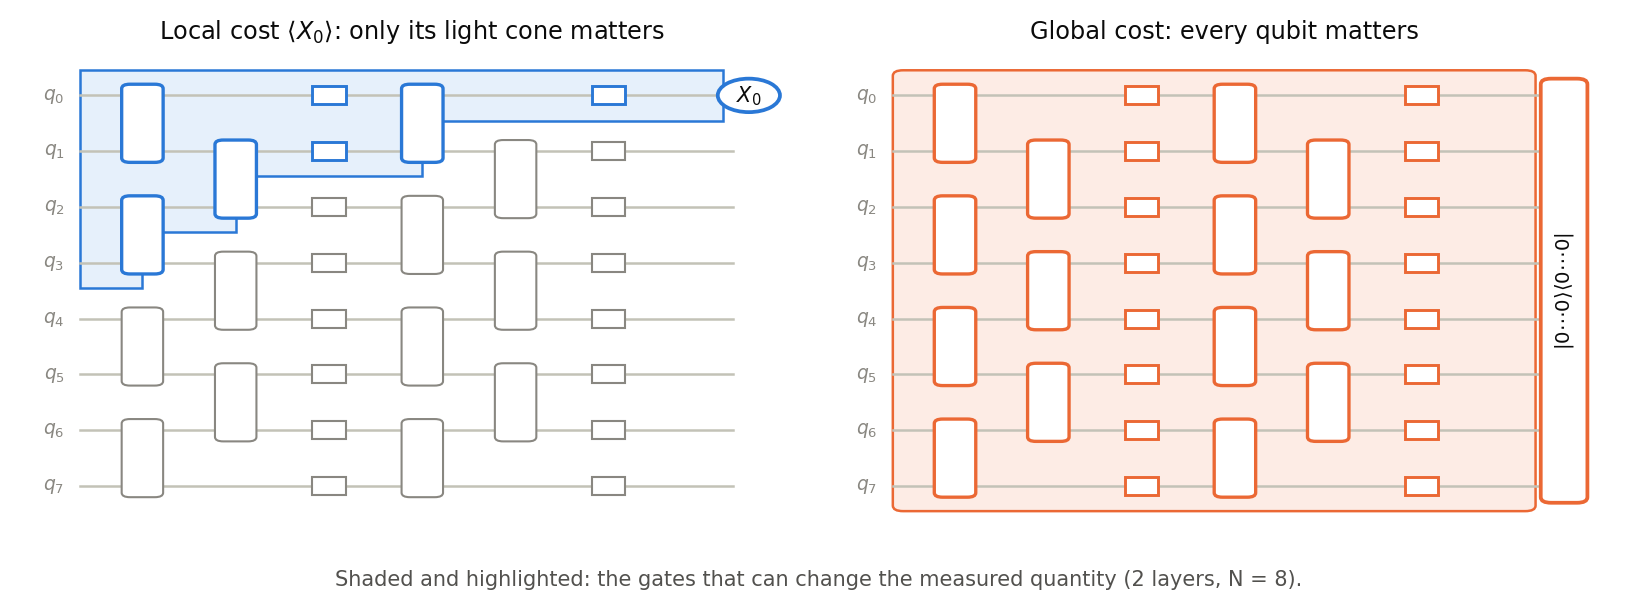

*References:* Calabrese & Cardy (2004), *Entanglement entropy and quantum field theory*, J. Stat. Mech. P06002. · Cerezo et al. (2021), *Cost function dependent barren plateaus in shallow parametrized quantum circuits*, Nat. Commun. 12, 1791.

epoch    0 | W1 >= 0.27967 | F = 0.69724 | |grad| = 0.1489
epoch   50 | W1 >= 0.27495 | F = 0.72979 | |grad| = 0.5074
epoch  100 | W1 >= 0.07483 | F = 0.88696 | |grad| = 0.4934
epoch  150 | W1 >= 0.00141 | F = 0.99294 | |grad| = 0.0028
epoch  200 | W1 >= 0.00055 | F = 0.99662 | |grad| = 0.0017
epoch  250 | W1 >= 0.00030 | F = 0.99835 | |grad| = 0.0011
epoch  299 | W1 >= 0.00021 | F = 0.99905 | |grad| = 0.0007


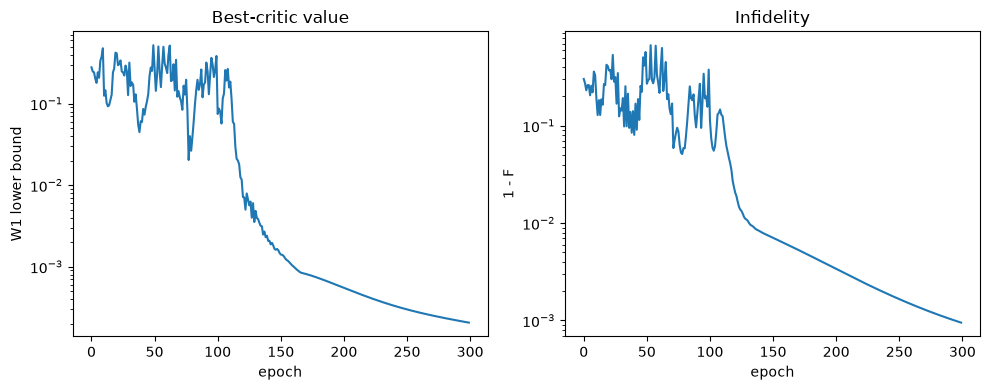

S exacta    = 0.4732 bits
S entrenada = 0.4753 bits
diferencia  = 0.0021 bits


In [9]:
# Section 4a: Training Execution and Entanglement Entropy
# Triga una estoneta en executar-se

def run_training(
    trainer: WQGANTrainer, num_epochs: int, lr_g: float = 2.0, lr_d: float = 0.5, log_every: int = 50
) -> Tuple[List[float], List[float]]:
    """TODO: call trainer.train_step num_epochs times; return (W1 lower bound history, fidelity history)."""
    w1_history = []
    fid_history = []
    for epoch in range(num_epochs):
        w1, fid, grad_norm = trainer.train_step(lr_g=lr_g, lr_d=lr_d)
        w1_history.append(w1)
        fid_history.append(fid)
        if epoch % log_every == 0 or epoch == num_epochs - 1:
            print(f"epoch {epoch:4d} | W1 >= {w1:.5f} | F = {fid:.5f} | |grad| = {grad_norm:.4f}")
    return w1_history, fid_history

# TODO:
#  1. create a WQGANTrainer called `trainer` for gen_circuit (Track B reuses trainer.theta);
trainer = WQGANTrainer(gen_circuit, theta_params, obs_pool, v_real, psi_exact)
 
#  2. train it for about 300 epochs (lr_g = 2.0 and lr_d = 0.5 work well) and plot both histories on a log scale;
w1_hist, fid_hist = run_training(trainer, num_epochs=300, lr_g=2.0, lr_d=0.5)

# Grafiques
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].semilogy(w1_hist)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("W1 lower bound"); ax[0].set_title("Best-critic value")
ax[1].semilogy(1 - np.array(fid_hist))
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("1 - F"); ax[1].set_title("Infidelity")
plt.tight_layout()
plt.show()

#  3. compare the half-chain entropy of the trained state with entropy_real.
psi_trained = Statevector(gen_circuit.assign_parameters(trainer.theta))
entropy_trained = compute_von_neumann_entropy(psi_trained, subsystem_A)
print(f"S exacta    = {entropy_real:.4f} bits")
print(f"S entrenada = {entropy_trained:.4f} bits")
print(f"diferencia  = {abs(entropy_real - entropy_trained):.4f} bits")

N =  6 | S = 0.473187 bits
N =  8 | S = 0.515275 bits
N = 10 | S = 0.546857 bits
N = 12 | S = 0.572052 bits
N = 14 | S = 0.592976 bits

Càrrega central estimada (c) = 0.5880
Valor teòric esperat (CFT)   = 0.5000
Calculant les variàncies...
Processant N = 4...
Processant N = 6...
Processant N = 8...
Processant N = 10...


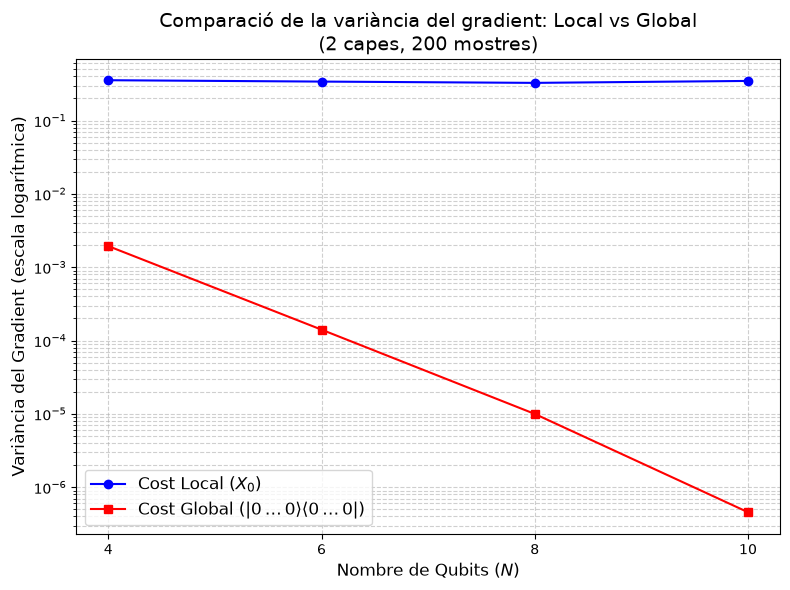

In [10]:
# Section 4b: CFT Check with Exact Diagonalization and Barren Plateau Ablation
def half_chain_entropy_ed(n: int) -> float:
    """Entropia de mitja cadena de l'estat fonamental crític, en bits."""

    if n < 2:
        raise ValueError("Calen almenys dos qubits per dividir la cadena.")

    # Construïm l'hamiltonià crític amb fronteres obertes.
    H = build_tfim_hamiltonian(n, J=1.0, h=1.0)

    # El representem com una matriu dispersa per estalviar memòria.
    H_sparse = H.to_matrix(sparse=True)

    # Calculem només l'autovector de l'energia més baixa.
    # k=1: volem un únic autovector.
    # which="SA": seleccionem el valor propi algebraicament més petit.
    energies, eigenvectors = eigsh(
      H_sparse,
      k=1,
      which="SA",
      tol=1e-10
    )

    # La primera columna conté l'estat fonamental.
    psi_ground = Statevector(eigenvectors[:, 0])

    # Conservem els primers n//2 qubits.
    subsystem_A = list(range(n // 2))

    # Calculem l'entropia d'aquesta meitat.
    return compute_von_neumann_entropy(psi_ground, subsystem_A)


def fit_central_charge(sizes: List[int], entropies: List[float]) -> float:
    """TODO: return c from 
        y = mx + b <--> S(N/2) = (c/6) log2 N + const
        m = c/6 """
    # 1. Convertim les nostres llistes en arrays de numpy per poder operar
    y = np.asarray(entropies, dtype=float)
    x = np.log2(np.asarray(sizes, dtype=float))  # Calculem el logaritme en base 2 de les mides N
    
    # 2. Fem la regressió lineal (ajust polinòmic de grau 1: y = mx + b)
    # np.polyfit ens retorna dos valors: la pendent (m) i la constant (b)
    m, b = np.polyfit(x, y, 1)
    
    # 3. Aïllem la càrrega central (c).
    # Com que sabem que la pendent m = c / 6, llavors c = m * 6
    c = m * 6.0
    
    return c
# A la segona funcio rebem una llista dels qubits usats per a calcular l'entropia de la cadena.
# Hi ha un model que ens diu que l'entropia (N/2) escala de manera lineal amb el logN.
# Aixi que el que muntem es una regressio lineal amb les dades, trobem el pendent i obtenim la c = central charge.
# Previament ja hem calculat l'entropia agafant nomes la meitat dels qubits de la cadena

def gradient_variance(num_qubits: int, num_layers: int, cost: str, num_samples: int, rng: np.random.Generator) -> float:
    """TODO: variance over random parameters of d<C>/d theta_0 (parameter-shift rule), for cost = "local"
    (C = X_0) or cost = "global" (C = |0...0><0...0|)."""
    raise NotImplementedError("TODO: gradient_variance")
# TODO:
#  1. compute the half-chain entropy for N = 6, 8, ..., 14 and fit the central charge (CFT: c = 0.5);
sizes = [6, 8, 10, 12, 14]
entropies = []

for n in sizes:
    entropy = half_chain_entropy_ed(n)
    entropies.append(entropy)

    print(f"N = {n:2d} | S = {entropy:.6f} bits")

c_estimada = fit_central_charge(sizes, entropies)

print(f"\nCàrrega central estimada (c) = {c_estimada:.4f}")
print("Valor teòric esperat (CFT)   = 0.5000")

def gradient_variance(num_qubits: int, num_layers: int, cost: str, num_samples: int, rng: np.random.Generator) -> float:
    """TODO: variance over random parameters of d<C>/d theta_0 (parameter-shift rule), for cost = "local"
    (C = X_0) or cost = "global" (C = |0...0><0...0|)."""

    # Construïm el circuit generador fent servir la funció definida a la Secció 2
    qc, params = create_z2_symmetric_generator(num_qubits, num_layers)
    num_params = len(params)
    
    # Preparem l'observable local si és necessari. 
    # Qiskit fa servir little-endian, així que X_0 va a la dreta de la cadena ('I...IX')
    if cost == "local":
        pauli_string = "I" * (num_qubits - 1) + "X"
        observable = SparsePauliOp(pauli_string)
        
    gradients = np.zeros(num_samples)
    
    for i in range(num_samples):
        # Generem valors aleatoris entre -pi i pi utilitzant el generador proporcionat
        theta_vals = rng.uniform(-np.pi, np.pi, num_params)
        
        # Apliquem la regla del desplaçament només sobre el primer paràmetre (theta_0)
        theta_plus = theta_vals.copy()
        theta_minus = theta_vals.copy()
        theta_plus[0] += np.pi / 2
        theta_minus[0] -= np.pi / 2
        
        # Obtenim els vectors d'estat exactes de Qiskit per a les configuracions desplaçades
        sv_plus = Statevector(qc.assign_parameters(theta_plus))
        sv_minus = Statevector(qc.assign_parameters(theta_minus))
        
        # Avaluem la funció de cost respectiva
        if cost == "local":
            # El cost local requereix el valor esperat de l'operador X_0
            exp_plus = sv_plus.expectation_value(observable).real
            exp_minus = sv_minus.expectation_value(observable).real
        elif cost == "global":
            # El cost global equival a projectar sobre l'estat base.
            # Això és exactament la probabilitat de trobar l'estat en |0...0>,
            # corresponent al mòdul al quadrat de la primera component (índex 0).
            exp_plus = np.abs(sv_plus.data[0])**2
            exp_minus = np.abs(sv_minus.data[0])**2
        else:
            raise ValueError("El paràmetre cost ha de ser 'local' o 'global'")
            
        # Calculem el gradient per la regla del desplaçament
        gradients[i] = (exp_plus - exp_minus) / 2.0
        
    # Retornem la variància de la distribució de gradients
    return float(np.var(gradients))


#  2. compare the gradient variance of the local and global costs for N = 4, 6, 8, 10
#     (2 layers, about 200 samples) and plot both on a log scale.

N_values = [4, 6, 8, 10]
num_layers = 2
num_samples = 200
rng = np.random.default_rng(42) 

variances_local = []
variances_global = []

print("Calculant les variàncies...")
for N in N_values:
    print(f"Processant N = {N}...")
    
    # Càlcul per al cost local
    var_loc = gradient_variance(N, num_layers, "local", num_samples, rng)
    variances_local.append(var_loc)
    
    # Càlcul per al cost global
    var_glob = gradient_variance(N, num_layers, "global", num_samples, rng)
    variances_global.append(var_glob)

plt.figure(figsize=(8, 6))

plt.plot(N_values, variances_local, marker='o', linestyle='-', label='Cost Local ($X_0$)', color='blue')
plt.plot(N_values, variances_global, marker='s', linestyle='-', label='Cost Global ($|0\\dots0\\rangle\\langle0\\dots0|$)', color='red')

# Apliquem l'escala logarítmica a l'eix Y per veure la dependència exponencial del cost global
plt.yscale('log')

plt.xlabel('Nombre de Qubits ($N$)', fontsize=12)
plt.ylabel('Variància del Gradient (escala logarítmica)', fontsize=12)
plt.title('Comparació de la variància del gradient: Local vs Global\n(2 capes, 200 mostres)', fontsize=14)
plt.xticks(N_values)
plt.legend(fontsize=12)
plt.grid(True, which="both", ls="--", alpha=0.6)

plt.tight_layout()
plt.show()

---
## Advanced Extension Track A: Thermal Mixed States via Thermofield Double Purification

### Theoretical Formalism
At finite inverse temperature $\beta = 1/(k_B T)$, many-body quantum states are non-pure statistical ensembles described by the density matrix:
$$\rho(\beta) = \frac{e^{-\beta H}}{\mathcal{Z}}, \quad \mathcal{Z} = \operatorname{Tr}\left[e^{-\beta H}\right]$$
A unitary circuit acting on a pure input state always produces a pure state, so preparing $\rho(\beta)$ requires auxiliary qubits. By Thermofield Dynamics, we double the Hilbert space to $\mathcal{H}_S \otimes \mathcal{H}_A$ using an ancilla register $A \cong S$ ($2N$ qubits total).
The pure **Thermofield Double (TFD)** state is:
$$\vert{}\psi_{\text{TFD}}(\beta)\rangle = \frac{1}{\sqrt{\mathcal{Z}}} \sum_{n} e^{-\beta E_n / 2} \vert{}n\rangle_S \vert{}\tilde{n}\rangle_A$$
Tracing out the ancilla register $A$ yields the exact thermal Gibbs state:
$$\operatorname{Tr}_A\left[ \vert{}\psi_{\text{TFD}}(\beta)\rangle\langle\psi_{\text{TFD}}(\beta)\vert{} \right] = \rho(\beta)$$

### Building the TFD Circuit
Bell pairs between $S_i$ and $A_i$ give the TFD state at infinite temperature ($\beta = 0$, $\rho_S = \mathbb{I}/2^N$). Gates acting only on $S$ can never change the eigenvalues of $\rho_S$, so the circuit must also contain gates that **couple each $S_i$ to its partner $A_i$** (here $R_{XX}$ and $R_{ZZ}$), interleaved with TFIM-like layers on $S$ and on $A$.

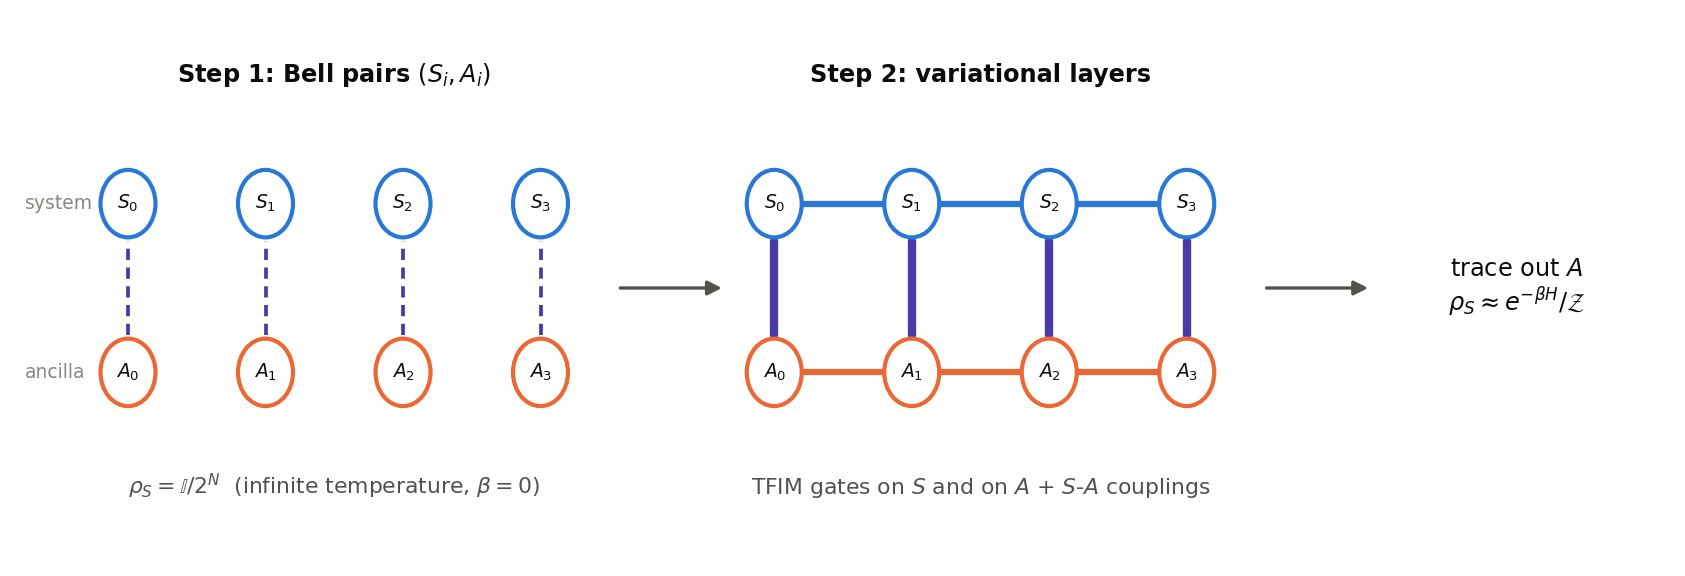

### Discriminator Adaptation for Mixed States
The discriminator pool acts strictly on the physical system register $S$:
$$\mathcal{O}_k^{(S)} \equiv \mathcal{O}_k \otimes I_A^{\otimes N}$$
This allows the W-QGAN to train on thermal expectation values without measuring the ancilla qubits. Matching these few expectation values does not by itself guarantee the thermal state; a simple remedy is to also minimize the free energy $F(\rho) = \operatorname{Tr}[\rho H] + \beta^{-1}\operatorname{Tr}[\rho \ln \rho]$, whose unique minimum is $\rho(\beta)$.

*Reference:* Wu & Hsieh (2019), *Variational thermal quantum simulation via thermofield double states*, Phys. Rev. Lett. 123, 220502.

In [ ]:
# Extension Track A: Thermal Gibbs State & Thermofield Double Architecture


def compute_thermal_gibbs_state(hamiltonian: SparsePauliOp, beta: float) -> DensityMatrix:
    """TODO: return rho(beta) = exp(-beta H) / Z."""
    raise NotImplementedError("TODO: compute_thermal_gibbs_state")


def create_tfd_generator(num_sys_qubits: int, num_layers: int) -> Tuple[QuantumCircuit, ParameterVector]:
    """TODO: return (circuit, parameters) for a 2N-qubit TFD ansatz with S = qubits 0..N-1 and A = qubits N..2N-1:
    Bell pairs (S_i, A_i), then num_layers layers of TFIM-like gates on S and on A plus gates that couple S_i to A_i.
    Use each parameter in exactly one gate."""
    raise NotImplementedError("TODO: create_tfd_generator")


# Verify Mixed Thermal State for N = 4 at beta = 1.0
N_SYS = 4
BETA = 1.0
H_sys = build_tfim_hamiltonian(N_SYS, J=1.0, h=1.0)
rho_gibbs = compute_thermal_gibbs_state(H_sys, beta=BETA)
tfd_qc, tfd_params = create_tfd_generator(N_SYS, num_layers=2)
assert np.isclose(rho_gibbs.purity().real, 0.3838, atol=1e-4), "Tr(rho^2) should be 0.3838 for N = 4, beta = 1"

# Check: the reduced state of S must change with the parameters (without S-A couplings it stays I / 2^N)
rng = np.random.default_rng(7)
purities = []
for _ in range(3):
    vals = rng.uniform(-np.pi, np.pi, len(tfd_params))
    sv = Statevector.from_instruction(tfd_qc.assign_parameters(dict(zip(tfd_params, vals))))
    purities.append(partial_trace(sv, list(range(N_SYS, 2 * N_SYS))).purity().real)
assert np.ptp(purities) > 1e-3, "rho_S does not depend on the parameters: the circuit cannot leave beta = 0"

# TODO: train the TFD generator so that rho_S approaches rho_gibbs (see the free-energy remark above).

---
## Advanced Extension Track B: IBM Quantum Deployment (Free-Tier Budget Strategy)

### The Free Tier Hardware Operational Constraint
Each team member's IBM Quantum Open Plan account includes a small free allocation of QPU time (10 minutes at the time of writing — check the current terms). Allocations are per account.
* **Anti-Pattern:** Do NOT run iterative training loops on the physical QPU. A 30-epoch training loop with parameter-shift gradients requires thousands of circuit executions, which would exhaust your entire team budget and suffer from queuing delays.
* **The Inference / Zero-In-The-Loop Paradigm:**
  1. Train your W-QGAN generator to convergence locally with the simulator.
  2. Bind the optimal parameters $\boldsymbol{\theta}^*$ to the circuit.
  3. Transpile the circuit **for the chosen backend** (an "ISA" circuit: native gates and qubit connectivity) and map the observables onto the physical qubits with `apply_layout`.
  4. Package all pool observables $\mathcal{S}$ into a **single Primitive Unified Bloc (PUB)** for Qiskit Runtime `EstimatorV2` and submit one job to an available QPU (select it with `service.least_busy(...)`; device names change over time).

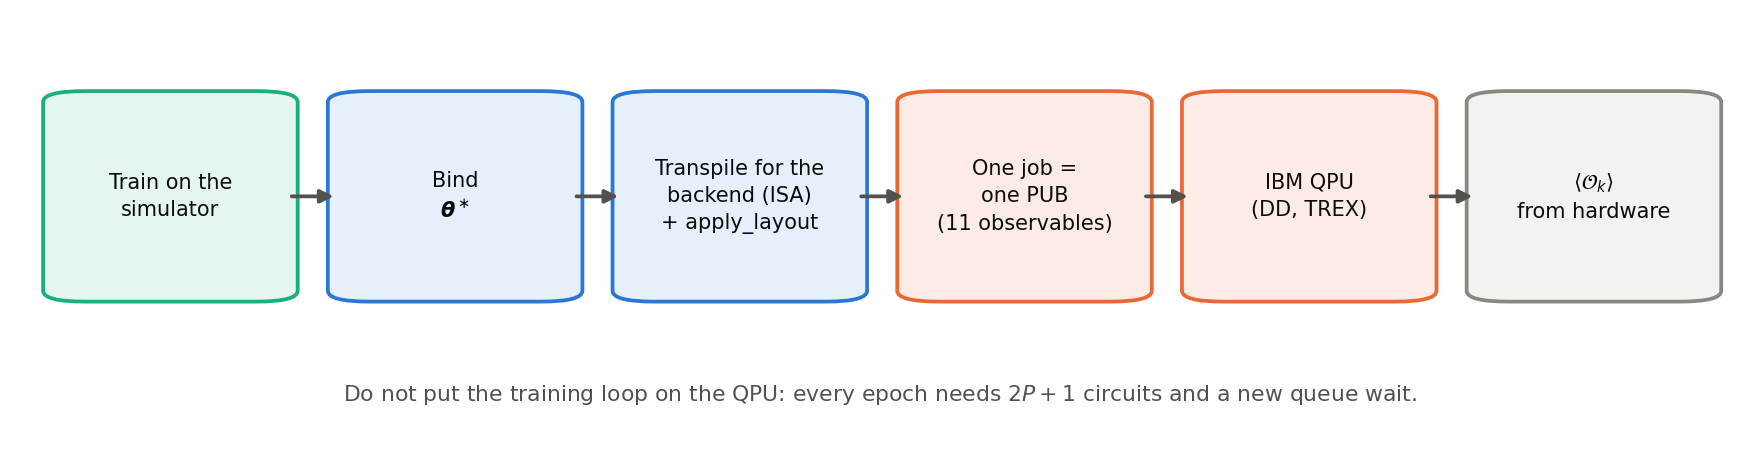

### Error Mitigation Requirements for Extension B
To claim full points in Track B, you must apply the following mitigation techniques in your Runtime configuration:
1. **PassManager Level 3 Optimization:** Routing and SWAP gate minimization for the heavy-hex topology.
2. **Dynamical Decoupling (DD):** Insert $XY4$ pulse sequences on idle qubits to mitigate environmental dephasing.
3. **Readout Mitigation (TREX):** Twirled readout error extinction to remove measurement bias.

*Useful APIs:* `QiskitRuntimeService(channel='ibm_quantum_platform')`, `service.least_busy(...)`, `generate_preset_pass_manager(backend=...)`, `SparsePauliOp.apply_layout`, `EstimatorV2(mode=backend, options=...)` with `EstimatorOptions` (`resilience_level`, `dynamical_decoupling`), `job.usage()`. The fake backends in `qiskit_ibm_runtime.fake_provider` (e.g. `FakeFez`) run the same code locally.

*Reference:* van den Berg, Minev & Temme (2022), *Model-free readout-error mitigation for quantum expectation values*, Phys. Rev. A 105, 032620.

In [11]:
# Extension Track B: IBM Quantum Deployment and Transpilation Pipeline
import warnings
from qiskit_ibm_runtime import EstimatorV2 as RuntimeEstimator
from qiskit_ibm_runtime.fake_provider import FakeFez

warnings.filterwarnings(
    "ignore", message="The EstimatorV2 class is deprecated"
)  # deprecated from qiskit-ibm-runtime 0.50

def prepare_hardware_pub(
    circuit: QuantumCircuit,
    optimal_theta: np.ndarray,
    param_vector: ParameterVector,
    observables: List[SparsePauliOp],
    backend,
) -> Tuple[QuantumCircuit, List[SparsePauliOp]]:
    """TODO: bind optimal_theta, transpile for `backend` (ISA circuit) and map the observables onto the physical
    qubits; return (isa_circuit, isa_observables)."""

    # Assignar els paràmetres al circuit de N qubits que volem fer funcionar
    circuit_assignat = circuit.assign_parameters(dict(zip(param_vector, optimal_theta)))
    # Transpilador, nivell d'optimització 3
    # pm==pass maneger 
    pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
    # Executar definitivament el circuït
    # Els isa==són el circuit i les mesures associades al hardware real i no portes abstractes, és traducció a la QPU
    # El run assigna les pass maneger que hem assignat al transpilador per a que ho processi sobre el nostre circuit quàntic
    isa_circuit=pm.run(circuit_assignat)

    isa_observables=[op.apply_layout(isa_circuit.layout) for op in observables]

    return isa_circuit, isa_observables

# Aquí optimitzem els paràmetres (angles) abans d'executar sobre l'ordinador quàntic (estalviem temps d'ordinador quàntic)
def estimate_on_backend(
    isa_circuit: QuantumCircuit, isa_observables: List[SparsePauliOp], backend, options: Optional[dict] = None
) -> np.ndarray:
    """TODO: run ONE Estimator job containing ONE PUB (isa_circuit, isa_observables); return the expectation values.
    With backend = FakeFez() it runs locally on a noisy simulator; with a real backend it uses your QPU time."""
    # Preparar l'estimador
    estimator=RuntimeEstimator(mode=backend)

    estimator.options.resilience_level = 1

    estimator.options.dynamical_decoupling.enable = True
    estimator.options.dynamical_decoupling.sequence_type = "XY4"
    # Unifica el circuit i les mesures del circuit en una sola entitat sobre la que fer treballar la QPU
    PUB=(isa_circuit, isa_observables)
    # Fer funcionar el l'estimator
    treball_simulador_ordinador_q=estimator.run([PUB])

    # Recopilar els resultats i retornar-los com un array
    resultats_PUB=treball_simulador_ordinador_q.result()[0]

    return np.array(resultats_PUB.data.evs)

In [12]:
# TODO: rehearse locally with FakeFez() and compare with trainer.evaluate_expectations(trainer.theta);
#       then one team member submits the same PUB to a real backend, with the error mitigation listed above.
#---
# 1. Instanciar el backend simulat amb soroll real

backend_fake = FakeFez()

# 2. Transpilar el circuit i mapejar els observables
isa_circuit_fake, isa_obs_fake = prepare_hardware_pub(
    circuit=gen_circuit,
    optimal_theta=trainer.theta,
    param_vector=theta_params,
    observables=obs_pool,
    backend=backend_fake
)

# 3. Executar la inferència sobre FakeFez
evs_fake = estimate_on_backend(isa_circuit_fake, isa_obs_fake, backend=backend_fake)

# 4. Obtenir les esperances ideals sense soroll
evs_ideal = trainer.evaluate_expectations(trainer.theta)

# 5. Comparativa de resultats resultats
print(f"Profunditat del circuit compilat (ISA): {isa_circuit_fake.depth()}")
print("\nComparació de valors esperats:")
for i, op in enumerate(obs_pool[:5]):  # Mostrem els primers 5
    print(f"Observable {i}: Ideal = {evs_ideal[i]:+.4f} | FakeFez = {evs_fake[i]:+.4f} | Dif = {abs(evs_ideal[i] - evs_fake[i]):.4f}")

c:\Anaconda\envs\notebook\Lib\site-packages\qiskit_ibm_runtime\fake_provider\local_service.py:187: UserWarning: The resilience_level option has no effect in local testing mode.
  warnings.warn("The resilience_level option has no effect in local testing mode.")
c:\Anaconda\envs\notebook\Lib\site-packages\qiskit_ibm_runtime\fake_provider\local_service.py:271: UserWarning: Options {'dynamical_decoupling': {'enable': True, 'sequence_type': 'XY4'}} have no effect in local testing mode.
  warnings.warn(f"Options {options_copy} have no effect in local testing mode.")


Profunditat del circuit compilat (ISA): 87

Comparació de valors esperats:
Observable 0: Ideal = +0.8549 | FakeFez = +0.8032 | Dif = 0.0516
Observable 1: Ideal = +0.7406 | FakeFez = +0.6821 | Dif = 0.0585
Observable 2: Ideal = +0.7170 | FakeFez = +0.6460 | Dif = 0.0710
Observable 3: Ideal = +0.7171 | FakeFez = +0.6577 | Dif = 0.0594
Observable 4: Ideal = +0.7407 | FakeFez = +0.6758 | Dif = 0.0650


In [13]:
from qiskit_ibm_runtime import QiskitRuntimeService

# 1. Connectar amb el compte gratuït d'IBM Quantum
# (Si no heu desat les credencials amb service.save_account, passeu token="EL_VOSTRE_TOKEN")
service = QiskitRuntimeService(channel="ibm_quantum_platform")

# 2. Escollir el processador quàntic real operatiu amb menys cua
backend_real = service.least_busy(operational=True, simulator=False)
print(f"QPU seleccionada: {backend_real.name}")

# 3. Transpilar específicament per a la QPU real escollida
isa_circuit_real, isa_obs_real = prepare_hardware_pub(
    circuit=gen_circuit,
    optimal_theta=trainer.theta,
    param_vector=theta_params,
    observables=obs_pool,
    backend=backend_real
)

# 4. Executar l'únic PUB a la màquina real
print("Enviant el treball a la QPU...")
evs_real = estimate_on_backend(isa_circuit_real, isa_obs_real, backend=backend_real)
print("Treball completat amb èxit!")

# 5. Mostrar la comparativa final (Ideal vs Fake vs Real)
print("\n--- Taula Comparativa Final ---")
for i in range(min(5, len(obs_pool))):
    print(f"Obs {i}: Ideal = {evs_ideal[i]:+.3f} | FakeFez = {evs_fake[i]:+.3f} | Real QPU = {evs_real[i]:+.3f}")

QPU seleccionada: ibm_fez
Enviant el treball a la QPU...
Treball completat amb èxit!

--- Taula Comparativa Final ---
Obs 0: Ideal = +0.855 | FakeFez = +0.803 | Real QPU = +0.786
Obs 1: Ideal = +0.741 | FakeFez = +0.682 | Real QPU = +0.709
Obs 2: Ideal = +0.717 | FakeFez = +0.646 | Real QPU = +0.692
Obs 3: Ideal = +0.717 | FakeFez = +0.658 | Real QPU = +0.707
Obs 4: Ideal = +0.741 | FakeFez = +0.676 | Real QPU = +0.681


findfont: Failed to find font weight medium, now using 400.


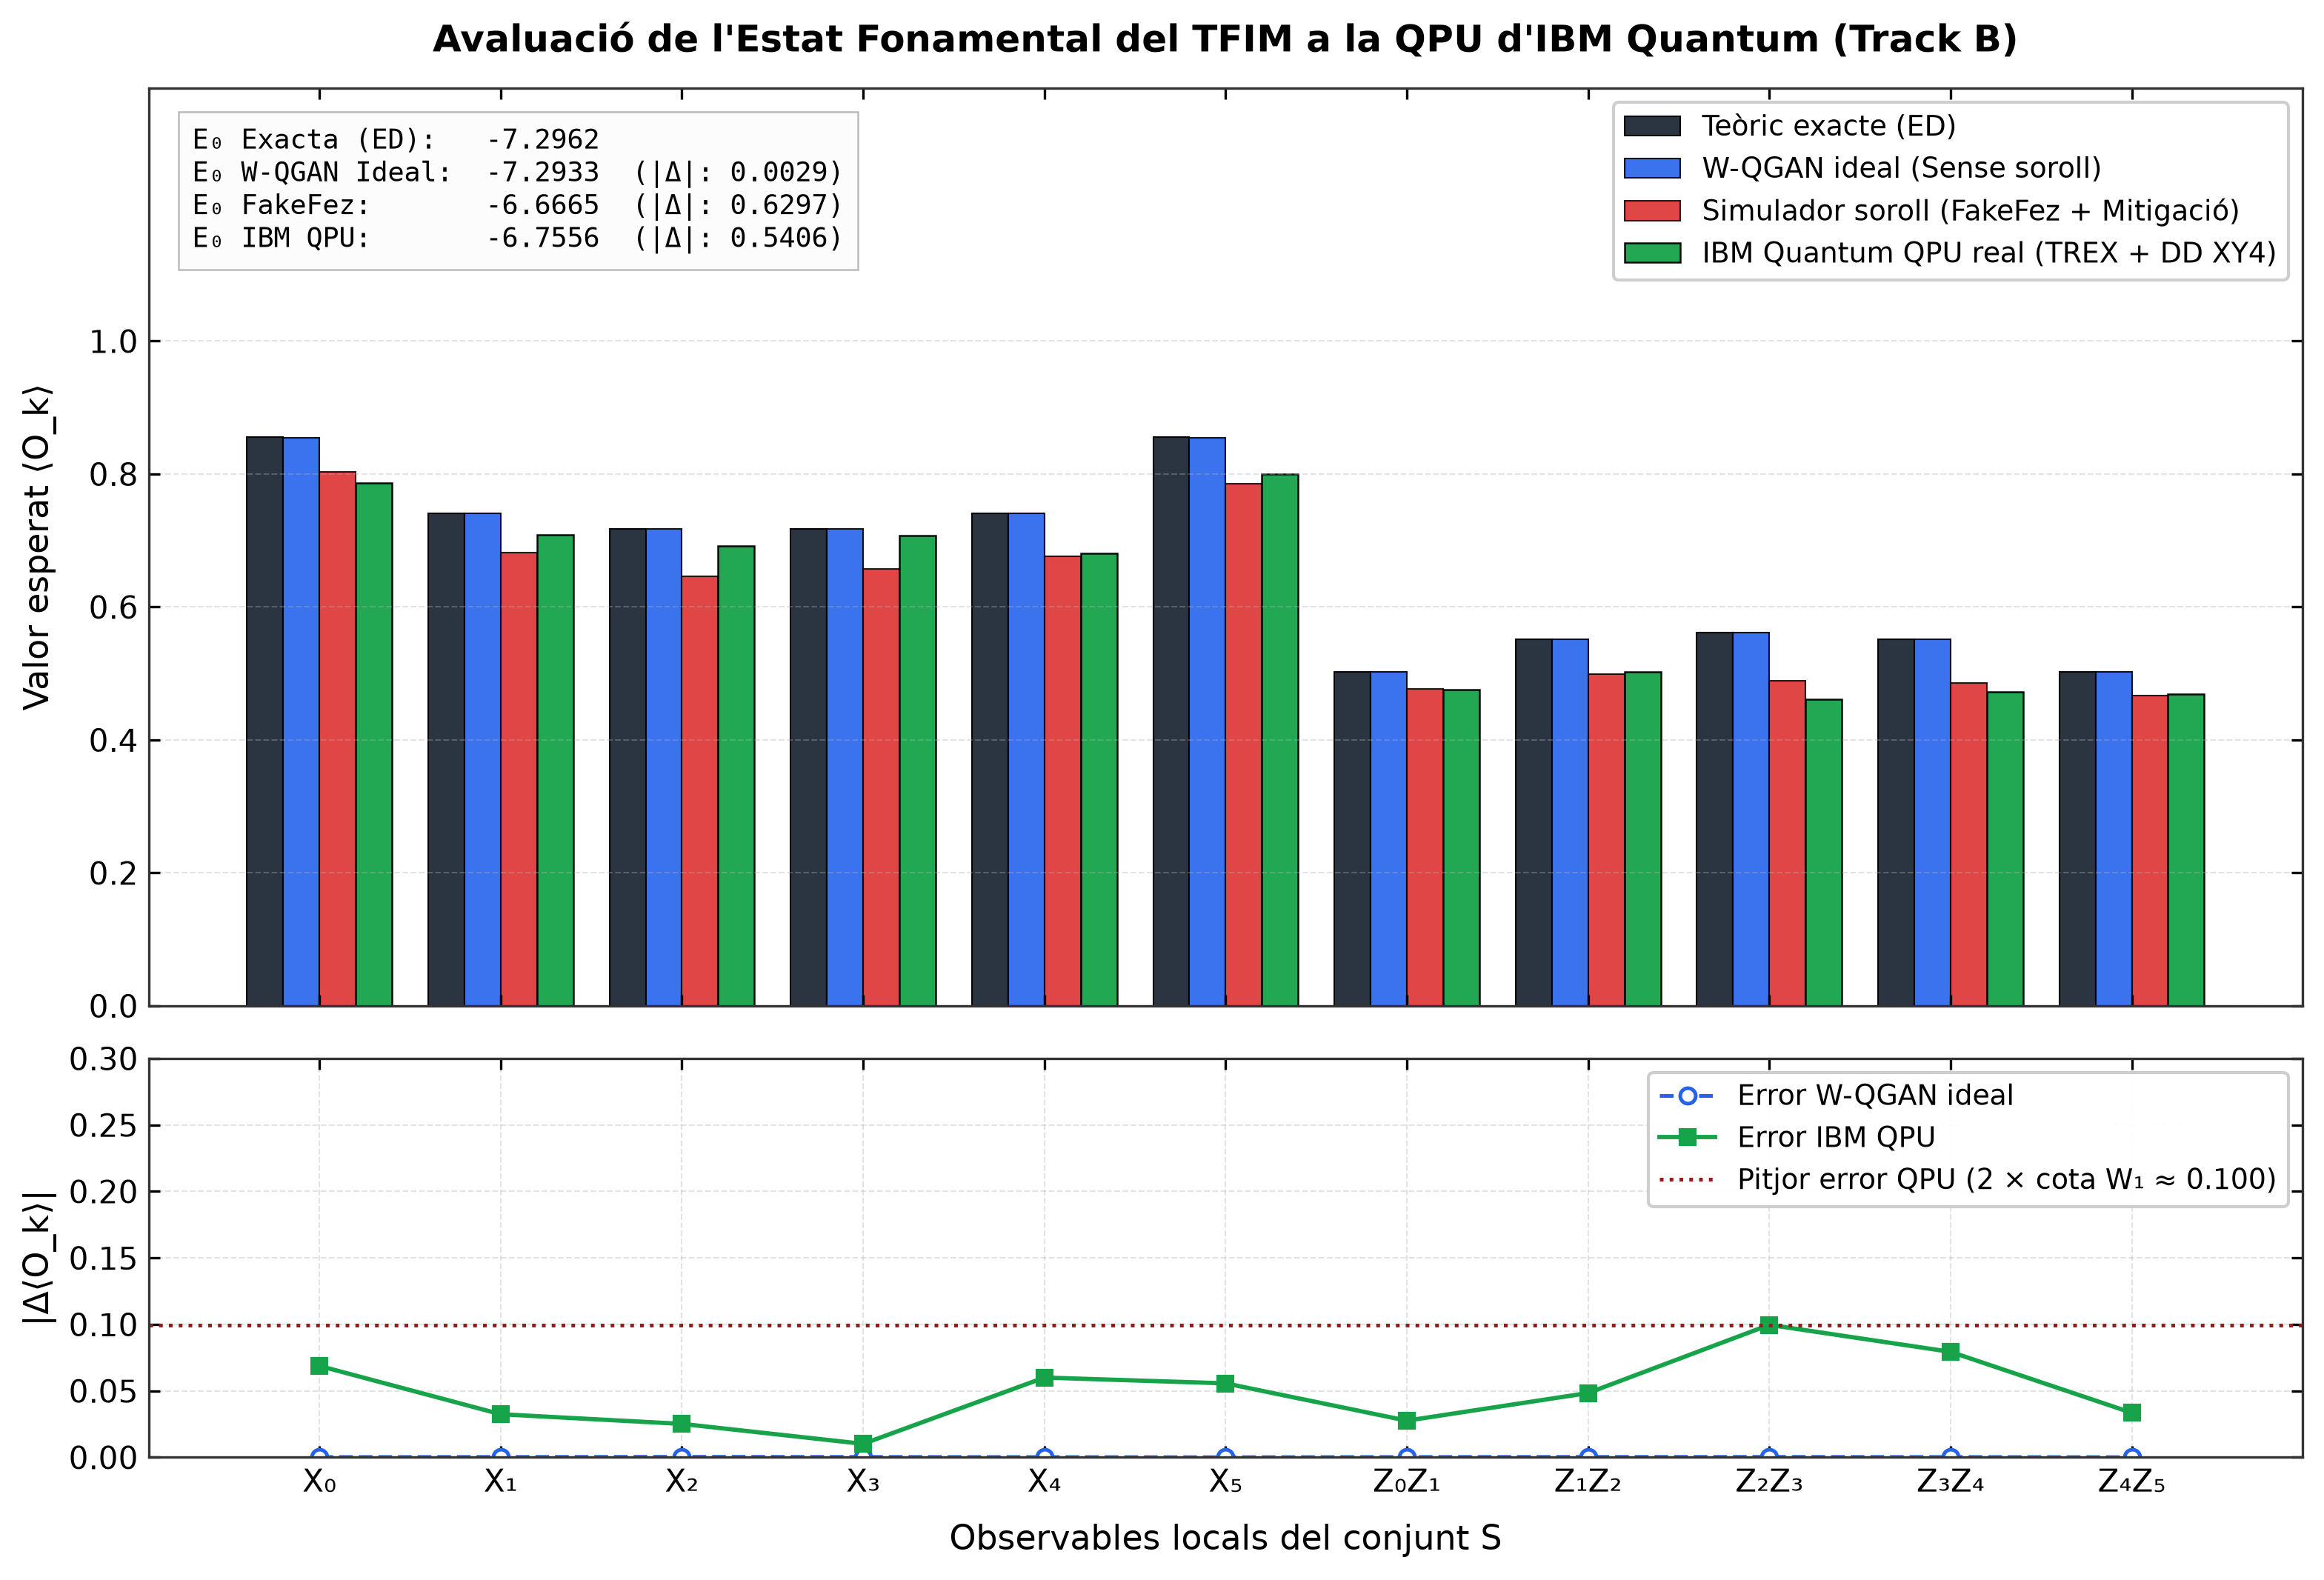

In [14]:
# ==============================================================================
# Panell Definitiu de Resultats de la QPU d'IBM Quantum (Layout Científic Net)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------------------------
# 1. CONFIGURACIÓ TIPOGRÀFICA
# ------------------------------------------------------------------------------
plt.rcParams.update(
    {
        "text.usetex": False,
        "font.family": "sans-serif",
        "font.sans-serif": [
            "DejaVu Sans",
            "Arial",
            "Helvetica",
            "Liberation Sans",
        ],
        "font.size": 10,
        "axes.edgecolor": "#333333",
        "axes.linewidth": 0.8,
    }
)

# ------------------------------------------------------------------------------
# 2. DEFINICIÓ D'ETIQUETES UNICODE (Subíndexs nets sense LaTeX)
# ------------------------------------------------------------------------------
n_q = N_QUBITS if "N_QUBITS" in locals() else 6
sub = str.maketrans("0123456789", "₀₁₂₃₄₅₆₇₈₉")

etiquetes_obs = [f"X{str(i).translate(sub)}" for i in range(n_q)] + [
    f"Z{str(i).translate(sub)}Z{str(i+1).translate(sub)}" for i in range(n_q - 1)
]

num_obs = len(etiquetes_obs)
x_pos = np.arange(num_obs)

if "evs_real" not in locals():
    print("Avís: 'evs_real' no trobat. Utilitzant 'evs_fake' com a demostració.")
    evs_real = evs_fake.copy()

# ------------------------------------------------------------------------------
# 3. RECONSTRUCCIÓ DE L'ENERGIA FONAMENTAL
# ------------------------------------------------------------------------------
energia_exacta = e_exact
energia_ideal = -float(np.sum(evs_ideal))
energia_fake = -float(np.sum(evs_fake))
energia_qpu = -float(np.sum(evs_real))

# ------------------------------------------------------------------------------
# 4. CONFIGURACIÓ DE LA FIGURA
# ------------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(12.5, 8.0),
    dpi=300,
    sharex=True,
    gridspec_kw={"height_ratios": [2.3, 1], "hspace": 0.08},
)

amplada = 0.20

# PANELL 1: Comparació de valors esperats
ax1.bar(
    x_pos - 1.5 * amplada,
    v_real,
    width=amplada,
    label="Teòric exacte (ED)",
    color="#1f2937",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.95,
)
ax1.bar(
    x_pos - 0.5 * amplada,
    evs_ideal,
    width=amplada,
    label="W-QGAN ideal (Sense soroll)",
    color="#2563eb",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.90,
)
ax1.bar(
    x_pos + 0.5 * amplada,
    evs_fake,
    width=amplada,
    label="Simulador soroll (FakeFez + Mitigació)",
    color="#dc2626",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.85,
)
ax1.bar(
    x_pos + 1.5 * amplada,
    evs_real,
    width=amplada,
    label="IBM Quantum QPU real (TREX + DD XY4)",
    color="#16a34a",
    edgecolor="black",
    linewidth=0.6,
    alpha=0.95,
)

# Configuració física d'escala: Inici estricte a 0 i sostre per a la llegenda
ax1.set_ylim(0.0, 1.38)
ax1.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax1.set_ylabel("Valor esperat ⟨O_k⟩", fontsize=11, fontweight="medium")
ax1.set_title(
    "Avaluació de l'Estat Fonamental del TFIM a la QPU d'IBM Quantum (Track B)",
    fontsize=12,
    pad=12,
    fontweight="bold",
)
ax1.grid(True, axis="y", linestyle="--", linewidth=0.5, alpha=0.35)
ax1.tick_params(direction="in", top=True, right=True, which="both")

# Llegenda situada a la zona d'aire superior dret (sense superposició)
ax1.legend(
    loc="upper right",
    frameon=True,
    facecolor="#ffffff",
    edgecolor="#cccccc",
    framealpha=0.95,
    fontsize=9,
)

# Quadre resum situat a la zona d'aire superior esquerre
text_resum = (
    f"E₀ Exacta (ED):   {energia_exacta:7.4f}\n"
    f"E₀ W-QGAN Ideal:  {energia_ideal:7.4f}  (|Δ|: {abs(energia_ideal - energia_exacta):.4f})\n"
    f"E₀ FakeFez:       {energia_fake:7.4f}  (|Δ|: {abs(energia_fake - energia_exacta):.4f})\n"
    f"E₀ IBM QPU:       {energia_qpu:7.4f}  (|Δ|: {abs(energia_qpu - energia_exacta):.4f})"
)
ax1.text(
    0.02,
    0.96,
    text_resum,
    transform=ax1.transAxes,
    fontsize=8.8,
    verticalalignment="top",
    fontfamily="monospace",
    bbox=dict(
        boxstyle="square,pad=0.5",
        facecolor="#fcfcfc",
        edgecolor="#bbbbbb",
        linewidth=0.6,
    ),
)

# ------------------------------------------------------------------------------
# PANELL 2: Residual d'error absolut |Mesurat - Teòric|
# ------------------------------------------------------------------------------
error_ideal = np.abs(evs_ideal - v_real)
error_qpu = np.abs(evs_real - v_real)
max_err = float(np.max(error_qpu))

ax2.plot(
    x_pos,
    error_ideal,
    "o--",
    color="#2563eb",
    label="Error W-QGAN ideal",
    markersize=5,
    linewidth=1.2,
    markerfacecolor="white",
    markeredgewidth=1.2,
)
ax2.plot(
    x_pos,
    error_qpu,
    "s-",
    color="#16a34a",
    label="Error IBM QPU",
    markersize=5,
    linewidth=1.4,
)

ax2.axhline(
    max_err,
    color="#991b1b",
    linestyle=":",
    linewidth=1.2,
    label=f"Pitjor error QPU (2 × cota W₁ ≈ {max_err:.3f})",
)

# Escala física d'error: Comença estrictament a 0 amb marge superior per a la llegenda
ax2.set_ylim(0.0, max(0.30, max_err * 1.55))
ax2.set_xlabel(
    "Observables locals del conjunt S", fontsize=11, fontweight="medium", labelpad=8
)
ax2.set_ylabel("|Δ⟨O_k⟩|", fontsize=11, fontweight="medium")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(etiquetes_obs, fontsize=10)
ax2.grid(True, linestyle="--", linewidth=0.5, alpha=0.35)
ax2.tick_params(direction="in", top=True, right=True, which="both")

ax2.legend(
    loc="upper right",
    frameon=True,
    facecolor="#ffffff",
    edgecolor="#cccccc",
    framealpha=0.95,
    fontsize=9,
)

# Alineació vertical dels eixos Y
fig.align_ylabels([ax1, ax2])

plt.show()

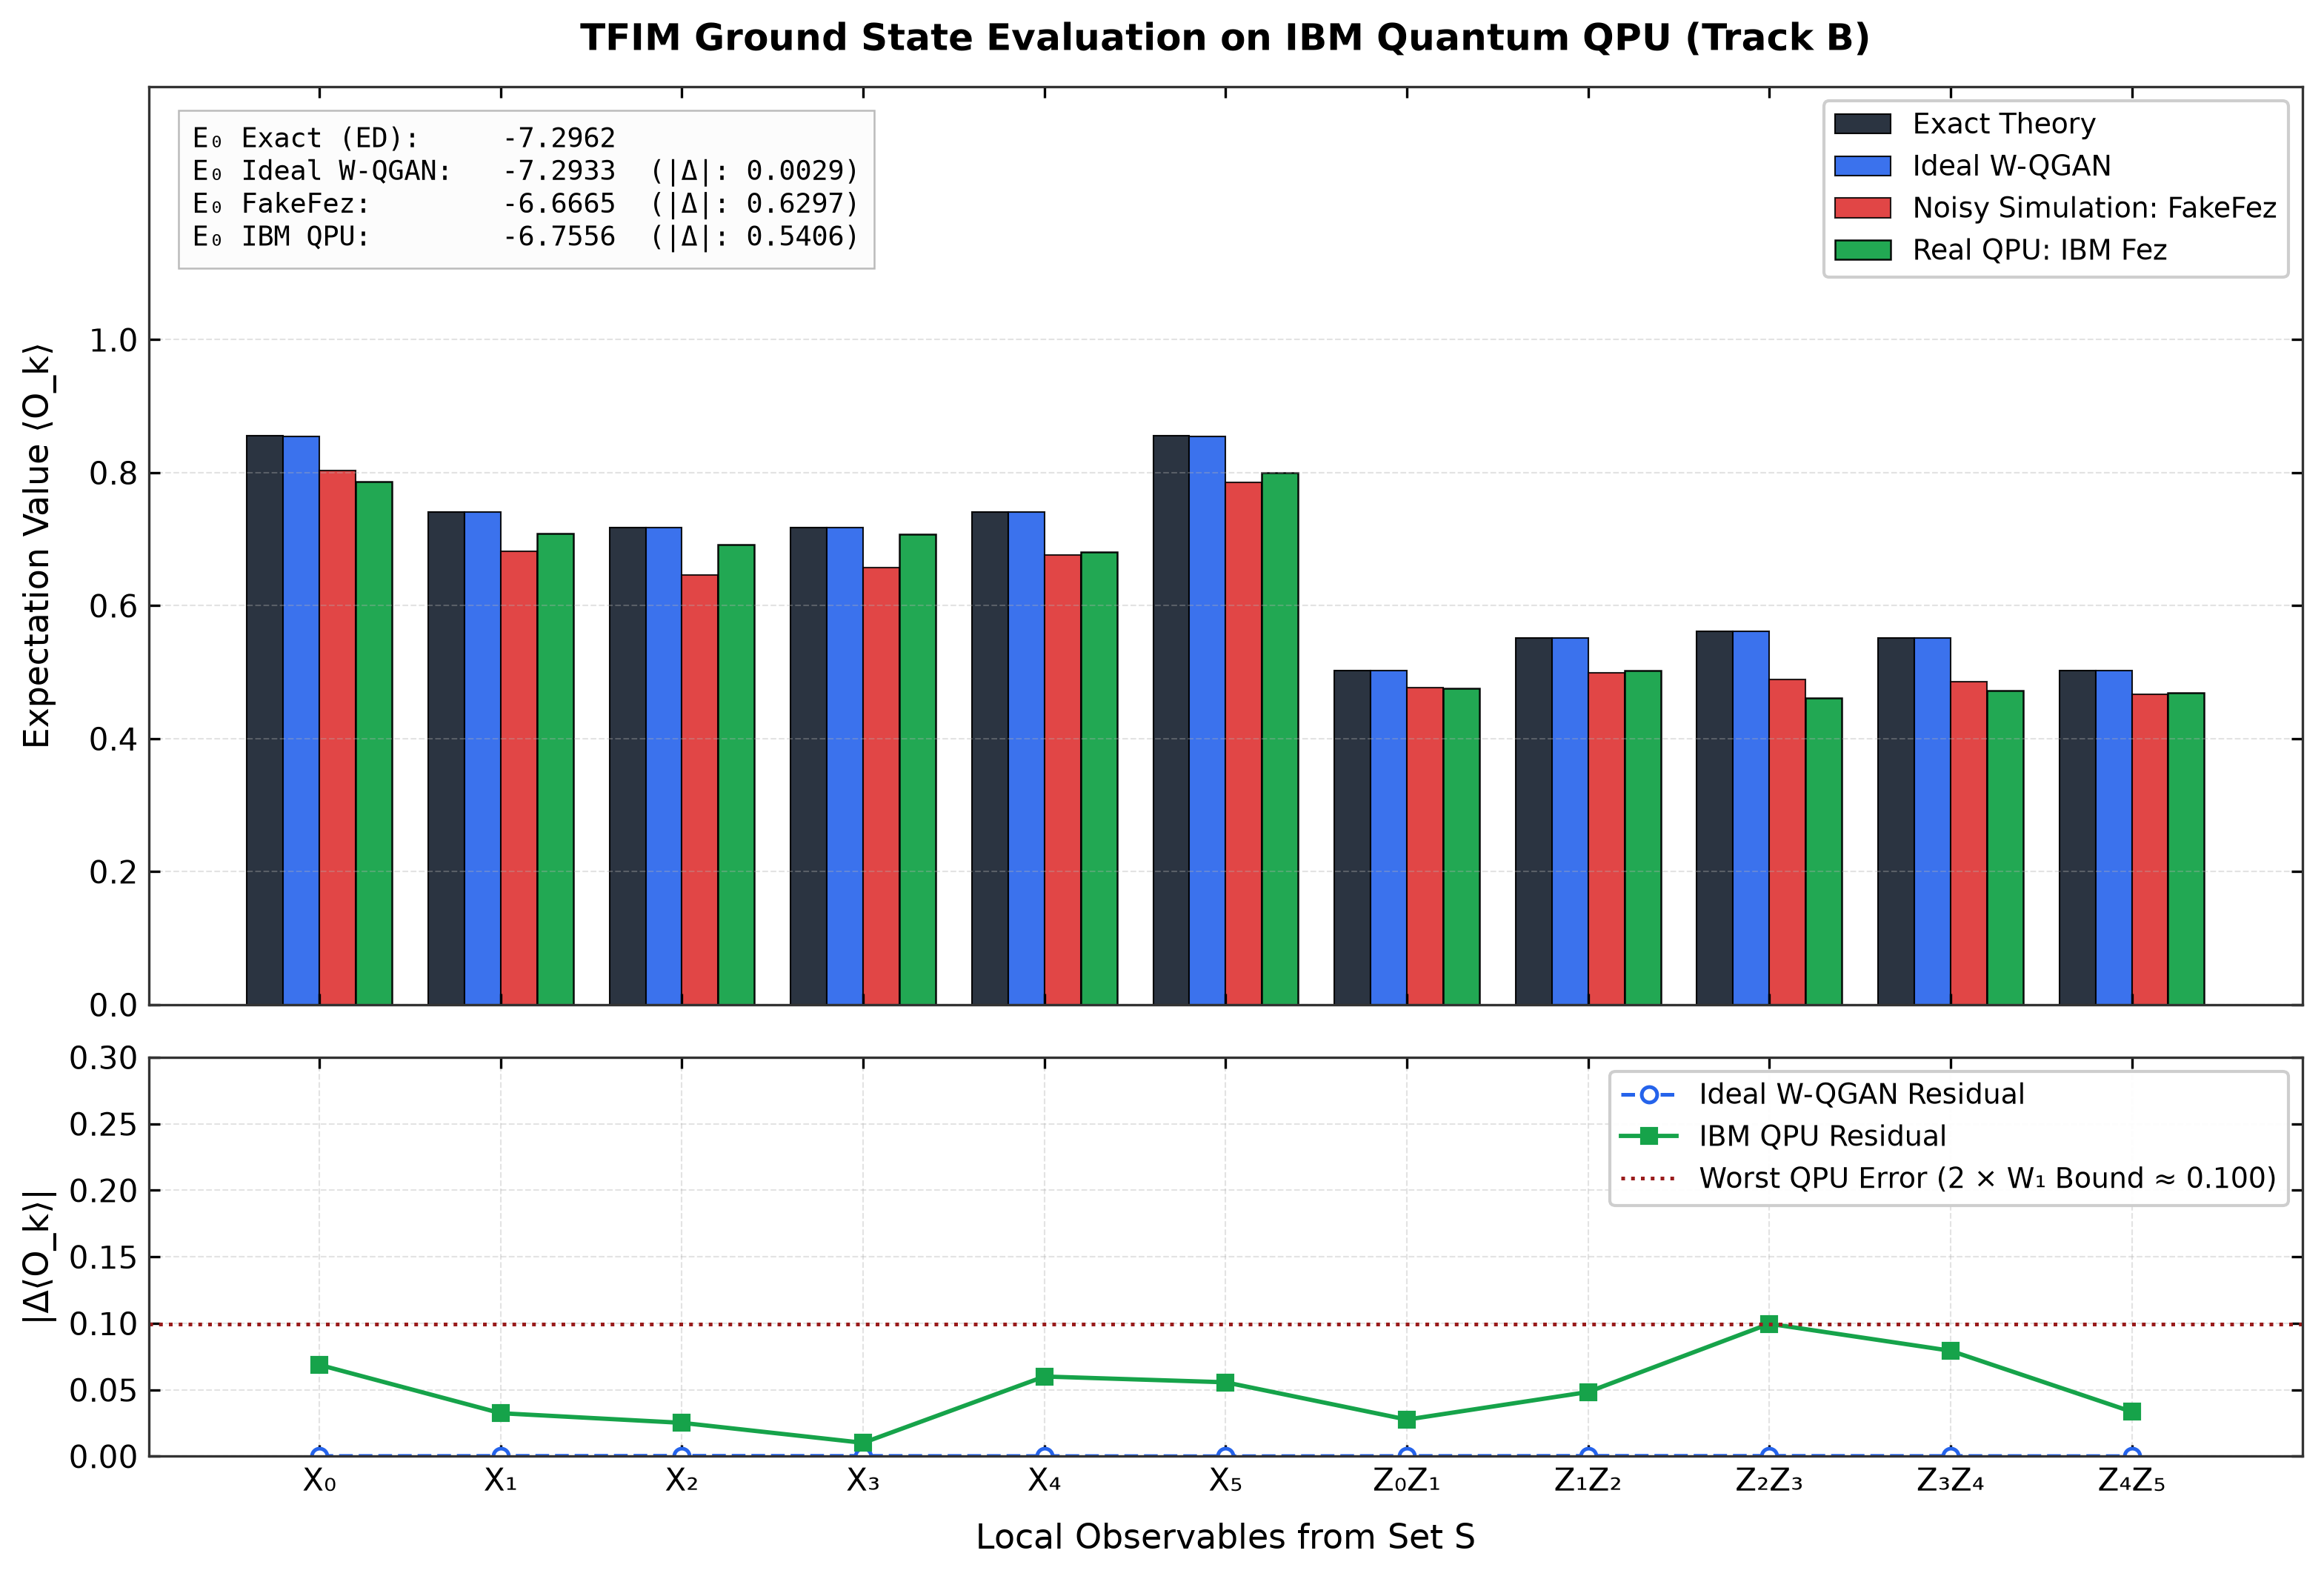

In [17]:
# ==============================================================================
# Definitive Results Panel: IBM Quantum QPU Evaluation (Track B)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------------------------
# 1. TYPOGRAPHIC AND SCIENTIFIC PLOT STYLING
# ------------------------------------------------------------------------------
plt.rcParams.update(
    {
        "text.usetex": False,
        "font.family": "sans-serif",
        "font.sans-serif": [
            "DejaVu Sans",
            "Arial",
            "Helvetica",
            "Liberation Sans",
        ],
        "font.size": 10,
        "axes.edgecolor": "#333333",
        "axes.linewidth": 0.8,
    }
)

# ------------------------------------------------------------------------------
# 2. UNICODE OBSERVABLE LABELS (Robust subscripts without LaTeX syntax)
# ------------------------------------------------------------------------------
n_q = N_QUBITS if "N_QUBITS" in locals() else 6
sub = str.maketrans("0123456789", "₀₁₂₃₄₅₆₇₈₉")

etiquetes_obs = [f"X{str(i).translate(sub)}" for i in range(n_q)] + [
    f"Z{str(i).translate(sub)}Z{str(i+1).translate(sub)}" for i in range(n_q - 1)
]

num_obs = len(etiquetes_obs)
x_pos = np.arange(num_obs)

if "evs_real" not in locals():
    print("Warning: 'evs_real' not found. Using 'evs_fake' as demonstration.")
    evs_real = evs_fake.copy()

# ------------------------------------------------------------------------------
# 3. GROUND STATE ENERGY RECONSTRUCTION
# ------------------------------------------------------------------------------
energia_exacta = e_exact
energia_ideal = -float(np.sum(evs_ideal))
energia_fake = -float(np.sum(evs_fake))
energia_qpu = -float(np.sum(evs_real))

# ------------------------------------------------------------------------------
# 4. FIGURE LAYOUT CONFIGURATION
# ------------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(12.5, 8.0),
    dpi=300,
    sharex=True,
    gridspec_kw={"height_ratios": [2.3, 1], "hspace": 0.08},
)

amplada = 0.20

# ------------------------------------------------------------------------------
# PANEL 1: Expectation Values Comparison
# ------------------------------------------------------------------------------
ax1.bar(
    x_pos - 1.5 * amplada,
    v_real,
    width=amplada,
    label="Exact Theory",
    color="#1f2937",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.95,
)
ax1.bar(
    x_pos - 0.5 * amplada,
    evs_ideal,
    width=amplada,
    label="Ideal W-QGAN",
    color="#2563eb",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.90,
)
ax1.bar(
    x_pos + 0.5 * amplada,
    evs_fake,
    width=amplada,
    label="Noisy Simulation: FakeFez",
    color="#dc2626",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.85,
)
ax1.bar(
    x_pos + 1.5 * amplada,
    evs_real,
    width=amplada,
    label="Real QPU: IBM Fez",
    color="#16a34a",
    edgecolor="black",
    linewidth=0.6,
    alpha=0.95,
)

# Physical y-limits: strictly non-negative ground state projection
ax1.set_ylim(0.0, 1.38)
ax1.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax1.set_ylabel("Expectation Value ⟨O_k⟩", fontsize=11, fontweight="medium")
ax1.set_title(
    "TFIM Ground State Evaluation on IBM Quantum QPU (Track B)",
    fontsize=12,
    pad=12,
    fontweight="bold",
)
ax1.grid(True, axis="y", linestyle="--", linewidth=0.5, alpha=0.35)
ax1.tick_params(direction="in", top=True, right=True, which="both")

ax1.legend(
    loc="upper right",
    frameon=True,
    facecolor="#ffffff",
    edgecolor="#cccccc",
    framealpha=0.95,
    fontsize=9,
)

# Energy summary box in top-left overhead margin
text_resum = (
    f"E₀ Exact (ED):     {energia_exacta:7.4f}\n"
    f"E₀ Ideal W-QGAN:   {energia_ideal:7.4f}  (|Δ|: {abs(energia_ideal - energia_exacta):.4f})\n"
    f"E₀ FakeFez:        {energia_fake:7.4f}  (|Δ|: {abs(energia_fake - energia_exacta):.4f})\n"
    f"E₀ IBM QPU:        {energia_qpu:7.4f}  (|Δ|: {abs(energia_qpu - energia_exacta):.4f})"
)
ax1.text(
    0.02,
    0.96,
    text_resum,
    transform=ax1.transAxes,
    fontsize=8.8,
    verticalalignment="top",
    fontfamily="monospace",
    bbox=dict(
        boxstyle="square,pad=0.5",
        facecolor="#fcfcfc",
        edgecolor="#bbbbbb",
        linewidth=0.6,
    ),
)

# ------------------------------------------------------------------------------
# PANEL 2: Absolute Residual Error |Measured - Theoretical|
# ------------------------------------------------------------------------------
error_ideal = np.abs(evs_ideal - v_real)
error_qpu = np.abs(evs_real - v_real)
max_err = float(np.max(error_qpu))

ax2.plot(
    x_pos,
    error_ideal,
    "o--",
    color="#2563eb",
    label="Ideal W-QGAN Residual",
    markersize=5,
    linewidth=1.2,
    markerfacecolor="white",
    markeredgewidth=1.2,
)
ax2.plot(
    x_pos,
    error_qpu,
    "s-",
    color="#16a34a",
    label="IBM QPU Residual",
    markersize=5,
    linewidth=1.4,
)

ax2.axhline(
    max_err,
    color="#991b1b",
    linestyle=":",
    linewidth=1.2,
    label=f"Worst QPU Error (2 × W₁ Bound ≈ {max_err:.3f})",
)

ax2.set_ylim(0.0, max(0.30, max_err * 1.55))
ax2.set_xlabel(
    "Local Observables from Set S", fontsize=11, fontweight="medium", labelpad=8
)
ax2.set_ylabel("|Δ⟨O_k⟩|", fontsize=11, fontweight="medium")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(etiquetes_obs, fontsize=10)
ax2.grid(True, linestyle="--", linewidth=0.5, alpha=0.35)
ax2.tick_params(direction="in", top=True, right=True, which="both")

ax2.legend(
    loc="upper right",
    frameon=True,
    facecolor="#ffffff",
    edgecolor="#cccccc",
    framealpha=0.95,
    fontsize=9,
)

# Vertical alignment of both Y axes
fig.align_ylabels([ax1, ax2])

plt.show()
# Guarda la imatge en alta resolució (PNG és ideal per a PowerPoint perquè no perd nitidesa al text)
fig.savefig("ibm_qpu_results.png", dpi=300, bbox_inches="tight")

In [16]:
# Guardar totes les dades clau a disc (fitxer .npz)
np.savez(
    "resultats_track_b5lay.npz",
    optimal_theta=trainer.theta,
    v_real=v_real,
    evs_ideal=evs_ideal,
    evs_fake=evs_fake,
    evs_real=evs_real,
    energia_exacta=e_exact,
)

# Si teniu l'objecte del treball quàntic, mostreu i anoteu el seu ID
if "treball_simulador_ordinador_q" in locals():
    print(f"ID del treball a IBM Quantum: {treball_simulador_ordinador_q.job_id()}")
    print("Aquest ID queda guardat al vostre historial de quantum.ibm.com.")

print("Dades desades amb èxit a 'resultats_track_b5lay.npz'!")

Dades desades amb èxit a 'resultats_track_b5lay.npz'!


---
## Advanced Extension Track C: High-Performance JAX Acceleration

### Why Standard Python Loops are a Bottleneck
Evaluating parameter-shift gradients sequentially requires $2 \times p$ quantum circuit evaluations per iteration. For $N = 10$ and $p = 50$, this requires 100 circuit executions per step. In standard Python, interpreter overhead dominates.

### The JAX Acceleration Principle
Using JAX, the statevector is represented as an $N$-dimensional complex tensor of shape $(2, 2, \dots, 2)$. Using `jax.vmap`, all $2p$ parameter-shifted circuits can be executed in a single vectorized call (compiled with `jax.jit`), which typically gives large speedups. Measure yours against the `WQGANTrainer` of Section 3.

In [ ]:
# Extension Track C: JAX Tensor Vectorization Concept Scaffold

try:
    import jax

    jax.config.update("jax_enable_x64", True)  # double precision, like the Qiskit simulators
    import jax.numpy as jnp

    JAX_AVAILABLE = True
except ImportError:
    JAX_AVAILABLE = False

if JAX_AVAILABLE:
    sigma_x = jnp.array([[0.0, 1.0], [1.0, 0.0]], dtype=jnp.complex128)
    sigma_z = jnp.array([[1.0, 0.0], [0.0, -1.0]], dtype=jnp.complex128)
    identity = jnp.eye(2, dtype=jnp.complex128)

    def apply_rx_jax(state: jnp.ndarray, angle: float, qubit: int) -> jnp.ndarray:
        """TODO: apply R_X(angle) to `qubit` of `state`, a statevector stored as a tensor of shape (2,)*N.
        Hint: Qiskit's qubit q is tensor axis N-1-q (N = state.ndim)."""
        raise NotImplementedError("TODO: apply_rx_jax")

    # Check against Qiskit on a random 3-qubit state, for every qubit
    rng = np.random.default_rng(0)
    vec = rng.normal(size=8) + 1j * rng.normal(size=8)
    vec /= np.linalg.norm(vec)
    for q in range(3):
        qc_check = QuantumCircuit(3)
        qc_check.rx(0.7, q)
        jax_result = np.asarray(apply_rx_jax(jnp.asarray(vec).reshape(2, 2, 2), 0.7, q)).reshape(-1)
        assert np.allclose(jax_result, Statevector(vec).evolve(qc_check).data), f"Wrong qubit ordering for qubit {q}"
    print(
        "JAX is installed and apply_rx_jax is verified. Teams pursuing Track C should replace the parameter-shift loop with jax.vmap."
    )
else:
    print("JAX is not installed in this environment (for example on Intel Macs); Track C needs it.")

# TODO: write the generator in JAX (the R_ZZ layers are diagonal phases), vectorize the 2P shifted evaluations with
#       jax.vmap and jax.jit, check the gradient against WQGANTrainer.compute_generator_gradient and time both.

JAX is not installed in this environment (for example on Intel Macs); Track C needs it.


---
## Advanced Extension Track D: Learning Hamiltonian Unitary Dynamics $U(t) = e^{-i H t}$

### Theoretical Problem Formulation
Instead of generating a single target ray $\vert{}\psi_0\rangle \in \mathcal{H}$, the generator must learn an unknown unitary channel:
$$\mathcal{E}_t(\rho) = U(t) \rho U(t)^\dagger, \quad U(t) = \exp(-i H t)$$
for a quench duration $t = \tau$ under the critical TFIM Hamiltonian.
The objective is to train a parameterized unitary $V(\boldsymbol{\theta})$ to maximize average gate fidelity over the Haar measure:
$$\bar{\mathcal{F}}(U(\tau), V(\boldsymbol{\theta})) \equiv \int_{\text{Haar}} d\psi \, \left\vert{} \langle \psi \vert{} U^\dagger(\tau) V(\boldsymbol{\theta}) \vert{} \psi \rangle \right\vert{}^2 \to 1$$

Participants can choose between two approaches:
* **Option D1: Choi–Jamiołkowski Isomorphism Track (Channel–State Duality on $2N$ Qubits)**
* **Option D2: Product-State Input Batching Track (Ensemble Learning on $N$ Qubits)**

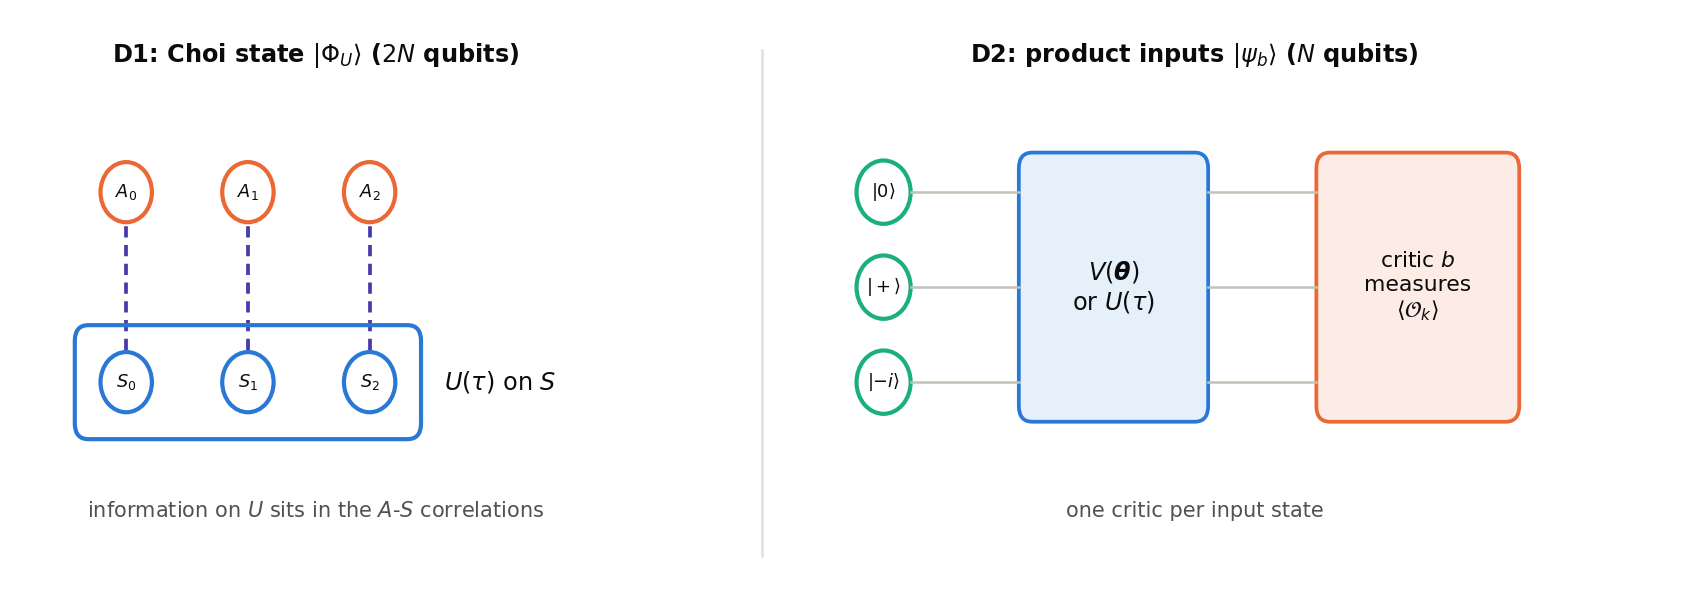

---

### Option D1: Choi–Jamiołkowski Isomorphism (Channel–State Formulation)
Any unitary channel $U$ on $N$ qubits corresponds to a maximally entangled pure state $\vert{}\Phi_U\rangle$ on $2N$ qubits ($\mathcal{H}_A \otimes \mathcal{H}_S$):
$$\vert{}\Phi_U\rangle = (\mathbb{I}_A \otimes U) \vert{}\Phi^+\rangle, \quad \vert{}\Phi^+\rangle = \bigotimes_{j=0}^{N-1} \frac{\vert{}00\rangle_{A_j S_j} + \vert{}11\rangle_{A_j S_j}}{\sqrt{2}}$$
* **Target Choi State:** $\vert{}\Phi_{U(\tau)}\rangle = (\mathbb{I}_A \otimes e^{-i H \tau}) \vert{}\Phi^+\rangle$
* **Generator Choi State:** $\vert{}\Phi_{V(\boldsymbol{\theta})}\rangle = (\mathbb{I}_A \otimes V(\boldsymbol{\theta})) \vert{}\Phi^+\rangle$
* **Entanglement-to-Gate Fidelity Relation:**
  $$F_e = \left\vert{} \langle \Phi_{U(\tau)} \vert{} \Phi_{V(\boldsymbol{\theta})} \rangle \right\vert{}^2 \implies \bar{\mathcal{F}}(U, V) = \frac{2^N F_e + 1}{2^N + 1}$$
* **Hint:** the reduced state of $\vert\Phi_U\rangle$ on $S$ alone (or on $A$ alone) is the same for every $U$, so the critic must measure observables acting on both registers.

In [ ]:
# Extension Track D1: Choi-Jamiołkowski State Generator (2N Qubits) ---
def create_choi_generator(num_sys_qubits: int, num_layers: int) -> Tuple[QuantumCircuit, ParameterVector]:
    """TODO: return (circuit, parameters): Bell pairs (A_i, S_i) with A = qubits 0..N-1 and S = qubits N..2N-1, then
    V(theta) on S made of num_layers layers [R_ZZ on neighbouring S qubits, R_X on every S qubit]."""
    raise NotImplementedError("TODO: create_choi_generator")


def compute_target_choi_state(hamiltonian: SparsePauliOp, tau: float) -> Statevector:
    """TODO: return (I_A (x) U_S)|Phi+> with U = exp(-i H tau), using the same registers as create_choi_generator."""
    raise NotImplementedError("TODO: compute_target_choi_state")


# Verification: N=3 Quench Simulation at tau = 0.5
N_DYN = 3
TAU = 0.5
H_dyn = build_tfim_hamiltonian(N_DYN, J=1.0, h=1.0)
target_choi_sv = compute_target_choi_state(H_dyn, tau=TAU)
choi_qc, choi_params = create_choi_generator(N_DYN, num_layers=2)
assert target_choi_sv.num_qubits == 2 * N_DYN and np.isclose(np.linalg.norm(target_choi_sv.data), 1.0), (
    "The Choi state lives on 2N qubits and must be normalized"
)


### Option D2: Product-State Input Batching (Ensemble Learning)
To avoid the $2N$-qubit overhead of the Choi representation, train on input states drawn from the products of single-qubit Pauli eigenstates $\{ \vert{}0\rangle, \vert{}1\rangle, \vert{}+\rangle, \vert{}-\rangle, \vert{}+i\rangle, \vert{}-i\rangle \}^{\otimes N}$. For $N \ge 2$ these $6^N$ states are *not* a 2-design, but they are enough to determine $U$.
* **Mini-Batch Objective:** In each epoch, sample a mini-batch of $B \ll 6^N$ input states $\{ \vert{}\psi_{\text{in}}^{(b)}\rangle \}_{b=1}^B$ and use **one critic per input state**:
  $$\mathcal{L}(\boldsymbol{\theta}, \boldsymbol{\phi}) = \frac{1}{B} \sum_{b=1}^B \sum_{k=1}^M \phi_k^{(b)} \left( \langle \psi_{\text{in}}^{(b)} \vert{} U^\dagger(\tau) \mathcal{O}_k U(\tau) \vert{} \psi_{\text{in}}^{(b)} \rangle - \langle \psi_{\text{in}}^{(b)} \vert{} V^\dagger(\boldsymbol{\theta}) \mathcal{O}_k V(\boldsymbol{\theta}) \vert{} \psi_{\text{in}}^{(b)} \rangle \right)$$
  (a single critic shared by all inputs only compares averaged outputs and cannot detect the error).
* **Hint:** every observable in $\{X_i, Z_i Z_{i+1}\}$ commutes with $\Pi$, so this pool cannot tell $V$ from $\Pi V$; add parity-odd observables such as $Z_i$.
* **Advantage:** Runs strictly on $N$ qubits, compatible with the IBM Quantum free allocation.

*Reference:* Nielsen (2002), *A simple formula for the average gate fidelity of a quantum dynamical operation*, Phys. Lett. A 303, 249.

In [ ]:
# Extension Track D2: Product Pauli-Eigenstate Mini-Batch Sampler (N Qubits) ---
def sample_pauli_eigenstate_circuit(num_qubits: int, rng: Optional[np.random.Generator] = None) -> QuantumCircuit:
    """TODO: return a circuit preparing a random product of the six Pauli eigenstates |0>, |1>, |+>, |->, |+i>, |-i>."""
    raise NotImplementedError("TODO: sample_pauli_eigenstate_circuit")


# Verification: N=3 Quench Simulation at tau = 0.5
N_DYN = 3
TAU = 0.5
H_dyn = build_tfim_hamiltonian(N_DYN, J=1.0, h=1.0)

print(
    f"Option D2 (Product inputs): Sampled Random Input Circuit Depth = {sample_pauli_eigenstate_circuit(N_DYN, np.random.default_rng(0)).depth()}"
)

---
## Advanced Extension Track E: Open problem!

If you have had time, to finish all above, understanding the concepts well to explain in a presentation in detail, preparing such presentation, etc... and still have some more time, this is for you!

Think of your own extension, and implement it to distinguish your group from the rest. The more ambitious the better! (If and LLM proposes an idea, it will most likely be the same for other groups, so try to not pick its first proposal hehe)

In [ ]:
# Extension Track E:


---
## Hackathon Evaluation Paradigm: On-Site Oral Presentation & Technical Defense

### Evaluation Structure
There is **no automated grading test suite**. Evaluation is conducted 100% on-site based on:
1. A **10-minute live slide presentation** and code walkthrough by the entire team.
2. A **5-minute technical Q&A / oral defense** with the academic jury.

---

### Oral Defense Probe Questions
Judges can ask similar questions during the presentation to verify genuine student comprehension:
1. *"Why does a global projector discriminator suffer from a barren plateau even at shallow circuit depth, and how does your local, bounded observable pool avoid it?"*
2. *"Prove algebraically why the two-qubit gate $R_{ZZ}(\theta)$ preserves $\mathbb{Z}_2$ spin-flip parity $\Pi = \bigotimes_{i=0}^{N-1} X_i$. Does $R_{YZ}(\theta)$ preserve it? Name a two-qubit rotation that breaks it."*
3. *"In the Thermofield Double purification (Track A), why is measuring observables exclusively on the physical system register $S$ equivalent to taking expectation values against the mixed Gibbs density matrix $\rho(\beta)$? Why does the circuit need gates that couple $S$ and $A$?"*
4. *"In Extension Track D, why does the pure Choi state $\vert{}\Phi_U\rangle$ in Option D1 completely characterize the action of $U(t)$ on all input states, whereas using only computational basis inputs $\{\vert{}z\rangle\}$ fails to determine the relative phases between the columns of $U$?"*
5. *"Given the free runtime budget on IBM Quantum, why is running an iterative VQE or GAN optimization loop on the physical hardware an anti-pattern, and what makes the single-PUB inference strategy viable?"*